# CARGA DE IMÁGENES

In [110]:
!pip install -q pydicom nibabel
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [111]:
import os, copy, math, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
import pydicom
import nibabel as nib
from scipy import stats

plt.rcParams.update({'figure.dpi': 90, 'axes.titlesize': 10, 'image.interpolation': 'nearest'})

BASE = "/content/drive/MyDrive/Colab Notebooks"
RUTA_FOTO = os.path.join(BASE, "ed-edd-eddy.jpg")      # ahora es una foto tomada con celular
RUTA_RM   = os.path.join(BASE, "BrainMRI/P01/P01_S3.0_t1_mprage_tra_p2_iso_GAD_.nii.gz")

# La carpeta de la tomografía tiene corchetes en el nombre: la buscamos con os.walk (glob los interpreta como patrón)
RUTA_TC = None
for carpeta in sorted(os.listdir(BASE)):
    if carpeta.startswith("20060101") and os.path.isdir(os.path.join(BASE, carpeta)):
        for raiz, carpetas, archivos in os.walk(os.path.join(BASE, carpeta), followlinks=True):
            if os.path.basename(raiz).startswith("Series 002") and any(a.endswith(".dcm") for a in archivos):
                RUTA_TC = raiz
                break
    if RUTA_TC:
        break

CORTE_RM = 80     # corte axial de la RM a la altura de la amígdala / hipocampo
CORTE_TC = 42     # corte axial de la TC: mesencéfalo y lóbulos temporales
TAM_PARCHE = 50   # zona homogénea de 50x50 para medir el ruido

for r in [RUTA_FOTO, RUTA_RM, RUTA_TC]:
    print("OK   " if r and os.path.exists(r) else "FALTA", r)

OK    /content/drive/MyDrive/Colab Notebooks/ed-edd-eddy.jpg
OK    /content/drive/MyDrive/Colab Notebooks/BrainMRI/P01/P01_S3.0_t1_mprage_tra_p2_iso_GAD_.nii.gz
OK    /content/drive/MyDrive/Colab Notebooks/20060101 000000 [ - CRANE POLYGONE]/Series 002 [CT - Crane SPC]


## IMAGEN PLANA
Una foto es una matriz **alto × ancho × 3** (R, G, B) con 8 bits por canal: 256 valores posibles. Si el píxel `[0,0]` tiene 4 valores, el cuarto es el **canal alfa** (transparencia) y lo quitamos.

**Tamaño:** una foto de celular tiene millones de píxeles y nuestra convolución con bucles `for` tardaría muchísimo. Por eso, **para los filtros**, la reducimos una sola vez a 512 píxeles de ancho. **El ruido lo medimos en la foto original** (sección de ruido), porque reducir promedia píxeles y bajaría el ruido artificialmente.

Modo: RGB | tamaño original: (902, 1600)
Píxel [0,0]: [11 14  7] → 3 valores
Reducida para procesar: 902x1600 → 512x908


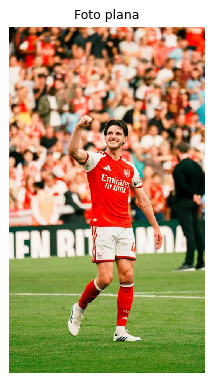

In [112]:
pil = Image.open(RUTA_FOTO)
print("Modo:", pil.mode, "| tamaño original:", pil.size)
foto_original = np.array(pil)
print("Píxel [0,0]:", foto_original[0][0], "→", len(foto_original[0][0]), "valores")
if foto_original.shape[2] == 4:
    print("Tiene canal alfa: nos quedamos con R, G, B")
    foto_original = foto_original[:, :, :3]

ANCHO = 512
if pil.size[0] > ANCHO:
    alto = round(pil.size[1] * ANCHO / pil.size[0])
    foto_rgb = np.array(Image.fromarray(foto_original).resize((ANCHO, alto)))
    print(f"Reducida para procesar: {foto_original.shape[1]}x{foto_original.shape[0]} → {ANCHO}x{alto}")
else:
    foto_rgb = foto_original.copy()

plt.figure(figsize=(5, 5)); plt.imshow(foto_rgb); plt.title("Foto plana"); plt.axis("off"); plt.show()

## IMAGEN RESONANCIA (NIfTI)
El NIfTI guarda todo el volumen 3D del paciente en un solo archivo (se convirtió desde DICOM). Del encabezado importan `dim` (número de vóxeles en x, y, z) y `pixdim` (mm por vóxel). **El tamaño del vóxel cambia entre pacientes**, así que toda medida en mm se hace con el `pixdim` de cada uno: *número de vóxeles × tamaño del vóxel*. La RM no tiene color ni unidades: son intensidades de señal electromagnética.

In [113]:
nifti = nib.load(RUTA_RM)
vol_rm = nifti.get_fdata()
h = nifti.header
dim = h["dim"][1:4]; pixdim = h["pixdim"][1:4]
print("dim    :", dim)
print("pixdim :", np.round(pixdim, 4), "mm")
print("tipo   :", h.get_data_dtype(), "| bits:", h["bitpix"], "| rango:", vol_rm.min(), "-", vol_rm.max())
print(f"Volumen de un vóxel: {np.prod(pixdim):.3f} mm³")
print(f"Ejemplo: 10 vóxeles en x = {10 * pixdim[0]:.2f} mm")

dim    : [224 256 176]
pixdim : [0.8984 0.8984 1.    ] mm
tipo   : int16 | bits: 16 | rango: 0.0 - 882.0
Volumen de un vóxel: 0.807 mm³
Ejemplo: 10 vóxeles en x = 8.98 mm


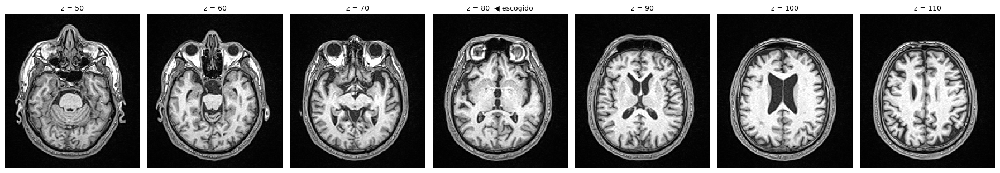

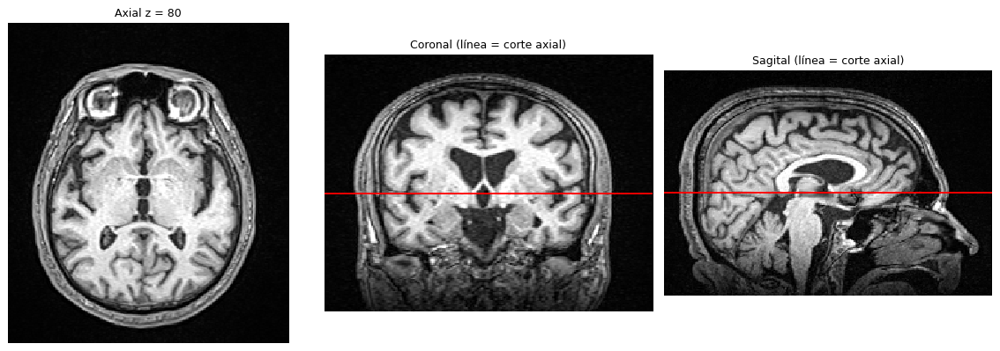

Corte RM: (256, 224) | rango: 0.0 - 764.0


In [114]:
# Recorremos cortes axiales alrededor del escogido para justificar la elección (sistema límbico)
vmax = np.percentile(vol_rm, 99.5)
cortes = list(range(CORTE_RM - 30, CORTE_RM + 31, 10))
fig, ax = plt.subplots(1, len(cortes), figsize=(20, 3.5))
for a, z in zip(ax, cortes):
    a.imshow(np.rot90(vol_rm[:, :, z]), cmap="gray", vmax=vmax)
    a.set_title(f"z = {z}" + ("  ◀ escogido" if z == CORTE_RM else "")); a.axis("off")
plt.tight_layout(); plt.show()

cx, cy = vol_rm.shape[0] // 2, vol_rm.shape[1] // 2
fig, ax = plt.subplots(1, 3, figsize=(13, 4.5))
ax[0].imshow(np.rot90(vol_rm[:, :, CORTE_RM]), cmap="gray", vmax=vmax); ax[0].set_title(f"Axial z = {CORTE_RM}")
ax[1].imshow(np.rot90(vol_rm[:, cy, :]), cmap="gray", vmax=vmax); ax[1].axhline(vol_rm.shape[2] - 1 - CORTE_RM, color="r"); ax[1].set_title("Coronal (línea = corte axial)")
ax[2].imshow(np.rot90(vol_rm[cx, :, :]), cmap="gray", vmax=vmax); ax[2].axhline(vol_rm.shape[2] - 1 - CORTE_RM, color="r"); ax[2].set_title("Sagital (línea = corte axial)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

img_rm = np.round(np.rot90(vol_rm[:, :, CORTE_RM])).astype(float)   # valores originales, sin normalizar
print("Corte RM:", img_rm.shape, "| rango:", img_rm.min(), "-", img_rm.max())

## IMAGEN TOMOGRAFÍA (DICOM)
Cada `.dcm` es una tajada. `pydicom.dcmread()` devuelve el encabezado como un **diccionario** (atributo → valor) y la matriz se obtiene con `pixel_array`. Ordenamos las tajadas por su posición real en z (`ImagePositionPatient`), no por el nombre del archivo.

In [115]:
def process_dicom(ds):
    campos = ["Modality", "Manufacturer", "SeriesDescription", "ConvolutionKernel", "Rows", "Columns",
              "PixelSpacing", "SliceThickness", "BitsAllocated", "BitsStored", "PixelRepresentation",
              "RescaleSlope", "RescaleIntercept", "WindowCenter", "WindowWidth", "KVP"]
    for campo in campos:
        if hasattr(ds, campo):
            print(f"{campo:20s}: {getattr(ds, campo)}")

archivos_tc = [os.path.join(RUTA_TC, f) for f in os.listdir(RUTA_TC) if f.endswith(".dcm")]
tajadas = [pydicom.dcmread(f) for f in archivos_tc]
tajadas.sort(key=lambda d: float(d.ImagePositionPatient[2]))
ds = tajadas[CORTE_TC]
print(f"{len(tajadas)} tajadas. Corte {CORTE_TC}: z = {float(ds.ImagePositionPatient[2]):.2f} mm\n")
process_dicom(ds)

142 tajadas. Corte 42: z = 33.25 mm

Modality            : CT
Manufacturer        : GE MEDICAL SYSTEMS
SeriesDescription   : Crane SPC
ConvolutionKernel   : SOFT
Rows                : 512
Columns             : 512
PixelSpacing        : [0.488281, 0.488281]
SliceThickness      : 1.250000
BitsAllocated       : 16
BitsStored          : 16
PixelRepresentation : 1
RescaleSlope        : 1
RescaleIntercept    : -1024
WindowCenter        : 40
WindowWidth         : 100
KVP                 : 120


**Qué significan los atributos clave**
- `PixelSpacing`: mm del mundo real por píxel. `SliceThickness`: grosor de la tajada.
- `BitsStored` = 16: hasta 65 536 valores. El monitor solo muestra 256, por eso se usa una **ventana** (`WindowCenter` / `WindowWidth`).
- `RescaleSlope` y `RescaleIntercept`: el valor guardado no está en HU. **HU = valor × slope + intercept**.
- `ConvolutionKernel` = SOFT: reconstruida para tejido blando (la serie "Osseux" usa BONEPLUS, para hueso).

**Anonimización:** vaciamos los datos del paciente y conservamos los técnicos (bits, fabricante, espaciado) y la institución, que se necesitan para procesar.

In [116]:
campos_paciente = ["PatientName", "PatientID", "PatientBirthDate", "PatientSex", "PatientAge",
                   "PatientAddress", "OtherPatientIDs", "ReferringPhysicianName"]
ds_anon = copy.deepcopy(ds)
for campo in campos_paciente:
    if campo in ds_anon:
        print(f"{campo:24s}: {str(ds_anon.data_element(campo).value)!r} → vacío")
        ds_anon.data_element(campo).value = ""
ds_anon.save_as("/content/tc_anonimizada.dcm")
print("\nGuardado: /content/tc_anonimizada.dcm")

PatientName             : 'Doe^Pierre' → vacío
PatientID               : '54879843' → vacío
PatientBirthDate        : '' → vacío
PatientSex              : 'M' → vacío
PatientAge              : '025Y' → vacío
ReferringPhysicianName  : '' → vacío

Guardado: /content/tc_anonimizada.dcm


Valores guardados (crudos): -2000 a 2743
En HU:                      -3024.0 a 1719.0

El crudo -2000 → -3024 HU NO es aire: es el relleno fuera del círculo de escaneo (21.3 % de la imagen).
Aire ≈ -1000 HU | agua = 0 HU | cerebro ≈ 20 a 45 HU | hueso > 300 HU
Centro del cerebro [256,256]: 28 HU


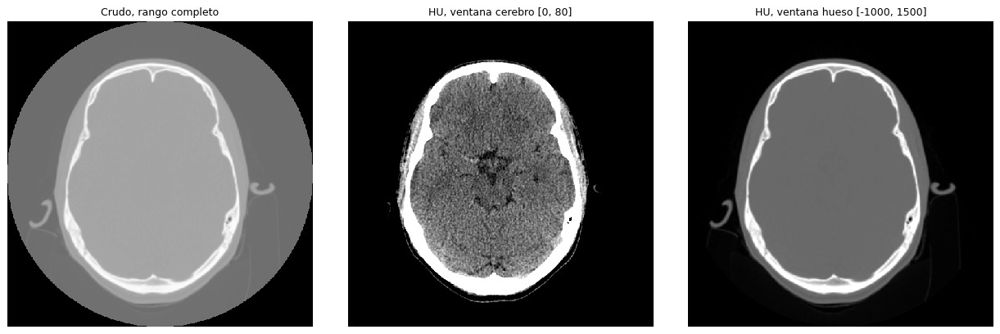

In [117]:
crudo = ds.pixel_array
hu = crudo.astype(float) * float(ds.RescaleSlope) + float(ds.RescaleIntercept)
RELLENO_TC = hu.min()
print("Valores guardados (crudos):", crudo.min(), "a", crudo.max())
print("En HU:                     ", hu.min(), "a", hu.max())
print(f"\nEl crudo -2000 → {RELLENO_TC:.0f} HU NO es aire: es el relleno fuera del círculo de escaneo ({(hu == RELLENO_TC).mean()*100:.1f} % de la imagen).")
print("Aire ≈ -1000 HU | agua = 0 HU | cerebro ≈ 20 a 45 HU | hueso > 300 HU")
print(f"Centro del cerebro [256,256]: {hu[256, 256]:.0f} HU")

fig, ax = plt.subplots(1, 3, figsize=(14, 4.5))
ax[0].imshow(crudo, cmap="gray"); ax[0].set_title("Crudo, rango completo")
ax[1].imshow(hu, cmap="gray", vmin=0, vmax=80); ax[1].set_title("HU, ventana cerebro [0, 80]")
ax[2].imshow(hu, cmap="gray", vmin=-1000, vmax=1500); ax[2].set_title("HU, ventana hueso [-1000, 1500]")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

Volumen TC: (142, 512, 512) | vóxel = 0.488 x 0.488 x 1.000 mm


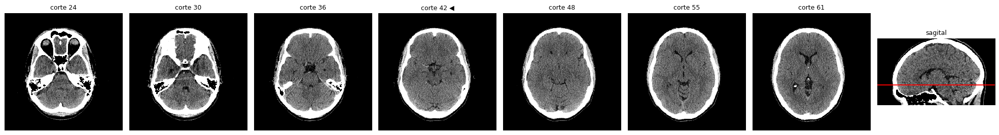

In [118]:
# Escoger el corte: recorrer el volumen y ver la altura (reconstrucción sagital)
vol_tc = np.stack([t.pixel_array.astype(float) * float(t.RescaleSlope) + float(t.RescaleIntercept) for t in tajadas])
dz = float(tajadas[1].ImagePositionPatient[2]) - float(tajadas[0].ImagePositionPatient[2])
dy = float(ds.PixelSpacing[0])
print("Volumen TC:", vol_tc.shape, f"| vóxel = {dy:.3f} x {dy:.3f} x {dz:.3f} mm")

cortes = [24, 30, 36, 42, 48, 55, 61]
fig, ax = plt.subplots(1, len(cortes) + 1, figsize=(22, 3.5))
for a, z in zip(ax, cortes):
    a.imshow(vol_tc[z], cmap="gray", vmin=0, vmax=80); a.set_title(f"corte {z}" + (" ◀" if z == CORTE_TC else "")); a.axis("off")
ax[-1].imshow(vol_tc[:, :, 256][::-1], cmap="gray", vmin=0, vmax=80, aspect=dz / dy)
ax[-1].axhline(len(tajadas) - 1 - CORTE_TC, color="r"); ax[-1].set_title("sagital"); ax[-1].axis("off")
plt.tight_layout(); plt.show()

img_tc = hu
del vol_tc

# TEORIA DE COLORES (solo la foto)
La RM y la TC **no tienen color**: miden señal o atenuación; el gris es solo como el monitor las pinta. Implementamos las fórmulas de clase **a mano**, píxel a píxel (en forma matricial):

- **Gris:** Y = 0,299 R + 0,587 G + 0,114 B. No es el promedio: el ojo es más sensible al verde.
- **YUV:** Y = luminancia (casi toda la información); U, V = crominancia, que se puede comprimir (transmisión).
- **HSV:** H = tono en grados (0–360°, círculo cromático); S = saturación = (máx − mín)/máx; V = brillo = máx(R, G, B).

In [119]:
def rgb_a_gris(rgb):
    R, G, B = rgb[:, :, 0].astype(float), rgb[:, :, 1].astype(float), rgb[:, :, 2].astype(float)
    return 0.299 * R + 0.587 * G + 0.114 * B

MATRIZ_YUV = np.array([[ 0.299,  0.587,  0.114],
                       [-0.147, -0.289,  0.436],
                       [ 0.615, -0.515, -0.100]])

def rgb_a_yuv(rgb):
    return rgb.astype(float) @ MATRIZ_YUV.T          # cada píxel [R,G,B] por la matriz 3x3

def rgb_a_hsv(rgb):
    x = rgb.astype(float) / 255
    R, G, B = x[:, :, 0], x[:, :, 1], x[:, :, 2]
    mx, mn = x.max(axis=2), x.min(axis=2)
    d = mx - mn
    dd = np.where(d == 0, 1, d)                       # evita dividir por 0 en los grises
    H = np.zeros_like(mx)
    es_r = (mx == R) & (d > 0)
    es_g = (mx == G) & (d > 0) & ~es_r
    es_b = (d > 0) & ~es_r & ~es_g
    H[es_r] = (60 * ((G - B) / dd) % 360)[es_r]
    H[es_g] = (60 * ((B - R) / dd) + 120)[es_g]
    H[es_b] = (60 * ((R - G) / dd) + 240)[es_b]
    S = np.where(mx == 0, 0, d / np.where(mx == 0, 1, mx))
    return np.dstack([H, S, mx])

gris = rgb_a_gris(foto_rgb)
yuv = rgb_a_yuv(foto_rgb)
hsv = rgb_a_hsv(foto_rgb)
promedio = foto_rgb.astype(float).mean(axis=2)

# Verificación a mano con un píxel
f, c = foto_rgb.shape[0] // 2, foto_rgb.shape[1] // 2
R, G, B = [int(v) for v in foto_rgb[f, c]]
print(f"Píxel [{f},{c}] = R {R}, G {G}, B {B}")
print(f"  Gris = 0.299·{R} + 0.587·{G} + 0.114·{B} = {0.299*R + 0.587*G + 0.114*B:.2f}  (función: {gris[f, c]:.2f})")
print(f"  HSV  = H {hsv[f, c, 0]:.1f}°, S {hsv[f, c, 1]:.3f}, V {hsv[f, c, 2]:.3f}  (V = máx/255 = {max(R, G, B)/255:.3f})")
print(f"Gris ponderado vs promedio simple: diferencia media {np.abs(gris - promedio).mean():.1f} niveles, máxima {np.abs(gris - promedio).max():.0f}")

Píxel [454,256] = R 251, G 1, B 3
  Gris = 0.299·251 + 0.587·1 + 0.114·3 = 75.98  (función: 75.98)
  HSV  = H 359.5°, S 0.996, V 0.984  (V = máx/255 = 0.984)
Gris ponderado vs promedio simple: diferencia media 9.3 niveles, máxima 27


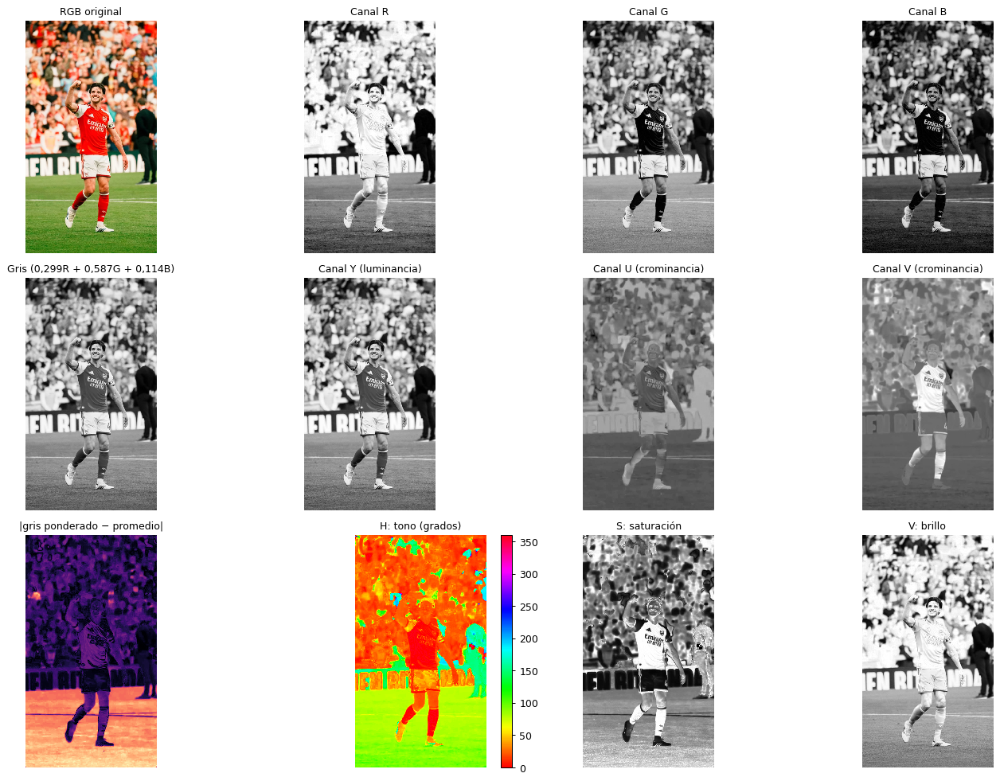

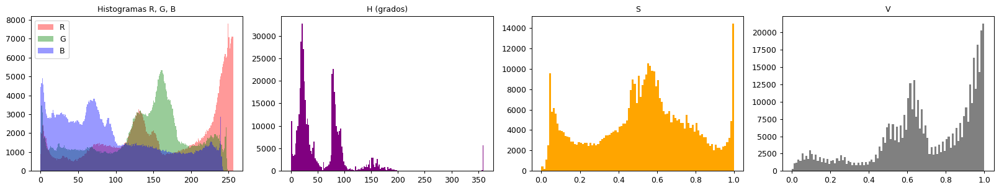

In [120]:
fig, ax = plt.subplots(3, 4, figsize=(16, 11))
ax[0, 0].imshow(foto_rgb); ax[0, 0].set_title("RGB original")
for k, n in enumerate("RGB"):
    ax[0, k + 1].imshow(foto_rgb[:, :, k], cmap="gray", vmin=0, vmax=255); ax[0, k + 1].set_title(f"Canal {n}")
ax[1, 0].imshow(gris, cmap="gray", vmin=0, vmax=255); ax[1, 0].set_title("Gris (0,299R + 0,587G + 0,114B)")
for k, n in enumerate("YUV"):
    ax[1, k + 1].imshow(yuv[:, :, k], cmap="gray"); ax[1, k + 1].set_title(f"Canal {n}" + (" (luminancia)" if n == "Y" else " (crominancia)"))
ax[2, 0].imshow(np.abs(gris - promedio), cmap="magma"); ax[2, 0].set_title("|gris ponderado − promedio|")
im = ax[2, 1].imshow(hsv[:, :, 0], cmap="hsv", vmin=0, vmax=360); ax[2, 1].set_title("H: tono (grados)"); plt.colorbar(im, ax=ax[2, 1], fraction=0.046)
ax[2, 2].imshow(hsv[:, :, 1], cmap="gray", vmin=0, vmax=1); ax[2, 2].set_title("S: saturación")
ax[2, 3].imshow(hsv[:, :, 2], cmap="gray", vmin=0, vmax=1); ax[2, 3].set_title("V: brillo")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(18, 3.5))
for k, (n, col) in enumerate(zip("RGB", ["red", "green", "blue"])):
    ax[0].hist(foto_rgb[:, :, k].ravel(), bins=256, range=(0, 256), color=col, alpha=0.4, label=n)
ax[0].legend(); ax[0].set_title("Histogramas R, G, B")
ax[1].hist(hsv[:, :, 0].ravel(), bins=180, range=(0, 360), color="purple"); ax[1].set_title("H (grados)")
ax[2].hist(hsv[:, :, 1].ravel(), bins=100, range=(0, 1), color="orange"); ax[2].set_title("S")
ax[3].hist(hsv[:, :, 2].ravel(), bins=100, range=(0, 1), color="gray"); ax[3].set_title("V")
plt.tight_layout(); plt.show()

**Qué se observa**
- **Y** (YUV) es prácticamente la imagen en gris: ahí está la estructura. **U y V** tienen poco detalle, por eso se pueden comprimir sin que se note.
- En **HSV** el color queda separado del brillo: **H** agrupa por tono aunque cambie la iluminación y **S** distingue colores vivos de grises. En las zonas sin saturación (blancos, negros, grises) el tono no está definido y H sale arbitrario.
- El gris ponderado difiere del promedio sobre todo en zonas muy verdes o muy azules.

Desde aquí la **foto se trabaja en gris** para compararla con la RM y la TC, que tienen un solo canal.

In [121]:
imgs = {"Foto": np.floor(gris), "RM": img_rm, "TC": img_tc}
VENTANA = {"Foto": (0, 255), "RM": (0, np.percentile(img_rm, 99.5)), "TC": (0, 80)}

def mostrar(ax, img, nombre, titulo=""):
    ax.imshow(img, cmap="gray", vmin=VENTANA[nombre][0], vmax=VENTANA[nombre][1])
    ax.set_title(titulo); ax.axis("off")

def recorte(img):
    # zona central para ver el detalle fino (solo para mostrar)
    H, W = img.shape
    return img[H // 4: 3 * H // 4, W // 4: 3 * W // 4]

for n, im in imgs.items():
    print(f"{n:4s}: {im.shape}, rango {im.min():.0f} a {im.max():.0f}")

Foto: (908, 512), rango 0 a 249
RM  : (256, 224), rango 0 a 764
TC  : (512, 512), rango -3024 a 1719


# HISTOGRAMA
El histograma cuenta cuántos píxeles tiene cada valor. En el eje horizontal:
- **Foto (8 bits):** 256 valores posibles (0–255).
- **RM y TC (16 bits):** hasta 65 536 valores. La TC además tiene valores negativos (HU).

La **CDF** (función de distribución acumulada) suma el histograma de izquierda a derecha y siempre crece de 0 a 1. Se lee: **"el p % de los píxeles tiene intensidad ≤ X"**.

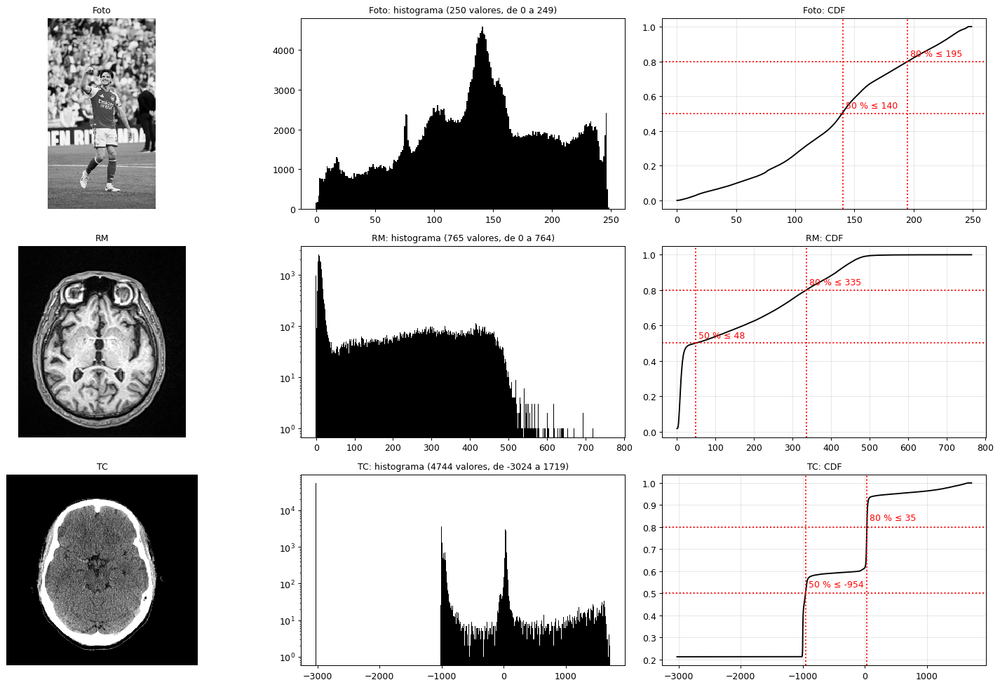

In [122]:
def calcular_histograma(imagen):
    # Cuenta píxel por píxel. Sirve para cualquier rango (también negativos): se desplaza por el mínimo.
    valores = np.floor(imagen).astype(int).ravel().tolist()
    minimo, maximo = min(valores), max(valores)
    conteo = [0] * (maximo - minimo + 1)
    for v in valores:
        conteo[v - minimo] += 1
    return list(range(minimo, maximo + 1)), conteo

def calcular_cdf(conteo):
    total = sum(conteo)
    cdf, acumulado = [], 0
    for c in conteo:
        acumulado += c
        cdf.append(acumulado / total)
    return cdf

def valor_en_percentil(valores, cdf, p):
    for v, F in zip(valores, cdf):
        if F >= p:
            return v

fig, ax = plt.subplots(3, 3, figsize=(17, 11))
for k, (n, im) in enumerate(imgs.items()):
    valores, conteo = calcular_histograma(im)
    cdf = calcular_cdf(conteo)
    mostrar(ax[k, 0], im, n, n)
    ax[k, 1].bar(valores, conteo, width=1, color="k")
    ax[k, 1].set_title(f"{n}: histograma ({len(valores)} valores, de {valores[0]} a {valores[-1]})")
    if n != "Foto": ax[k, 1].set_yscale("log")
    ax[k, 2].plot(valores, cdf, "k"); ax[k, 2].grid(alpha=.3); ax[k, 2].set_title(f"{n}: CDF")
    for p in [0.5, 0.8]:
        x = valor_en_percentil(valores, cdf, p)
        ax[k, 2].axhline(p, ls=":", c="r"); ax[k, 2].axvline(x, ls=":", c="r")
        ax[k, 2].text(x, p + 0.03, f" {int(p*100)} % ≤ {x}", color="r")
plt.tight_layout(); plt.show()

In [123]:
# Lectura de los picos de la TC con los rangos de Hounsfield vistos en clase
valores, conteo = calcular_histograma(imgs["TC"])
total = sum(conteo)
for nombre, a, b in [("relleno fuera del FOV", -3100, -2000), ("aire", -1100, -900), ("grasa", -150, -50),
                     ("agua / LCR", -5, 15), ("tejido cerebral", 20, 45), ("hueso", 300, 3100)]:
    pct = sum(c for v, c in zip(valores, conteo) if a <= v <= b) / total * 100
    print(f"{nombre:22s} [{a:6d}, {b:5d}] HU: {pct:5.1f} %")

relleno fuera del FOV  [ -3100, -2000] HU:  21.3 %
aire                   [ -1100,  -900] HU:  35.9 %
grasa                  [  -150,   -50] HU:   0.7 %
agua / LCR             [    -5,    15] HU:   1.6 %
tejido cerebral        [    20,    45] HU:  25.2 %
hueso                  [   300,  3100] HU:   5.4 %


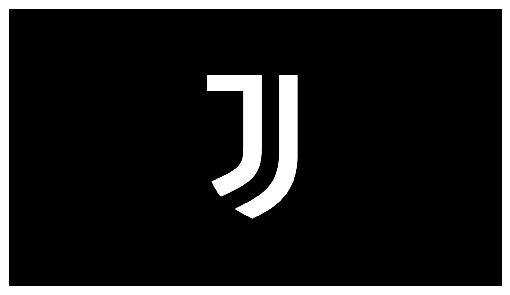

In [124]:
# Imagen de referencia de clase para leer el histograma
plt.figure(figsize=(8, 4)); plt.imshow(Image.open(os.path.join(BASE, "juve.png"))); plt.axis("off"); plt.show()

**Cómo se leen**
- **Foto:** izquierda = sombras, centro = medios tonos, derecha = altas luces. Cargado a la izquierda = subexpuesta; a la derecha = sobreexpuesta. Lo ideal es concentrarse en los medios tonos.
- **TC:** cada pico es un tejido: un pico aislado en ≈ −3024 HU (relleno), otro en ≈ −1000 (aire), uno grande en 20–45 HU (cerebro) y la cola del hueso. El cerebro ocupa una franja estrechísima del rango: por eso hay que usar ventana para verlo.
- **RM:** un pico enorme cerca de 0 (fondo) y la señal del tejido a la derecha. En pantalla se ve oscura porque los 16 bits se comprimen a 256 niveles; el histograma muestra los valores reales.

# ECUALIZACIÓN DEL HISTOGRAMA
Redistribuye las intensidades para que el histograma quede lo más plano posible (la CDF se vuelve una recta) y se aproveche todo el rango.

**Método (a mano):** 1) histograma y CDF; 2) cada valor *v* se reemplaza por
$$s = \left\lfloor (L-1)\,\frac{CDF(v) - CDF_{min}}{1 - CDF_{min}} \right\rfloor, \quad L = 256$$
Los valores muy frecuentes quedan separados entre sí y los poco frecuentes se juntan.

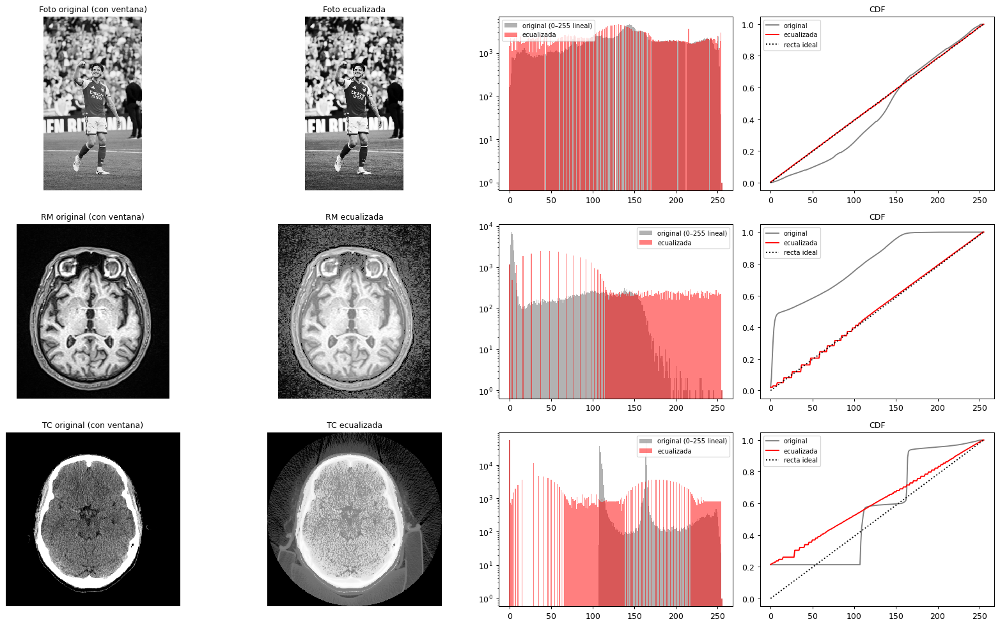

In [125]:
def ecualizar(imagen, L=256):
    valores, conteo = calcular_histograma(imagen)
    cdf = calcular_cdf(conteo)
    cdf_min = next(F for F, c in zip(cdf, conteo) if c > 0)
    tabla = [math.floor((L - 1) * (F - cdf_min) / (1 - cdf_min)) for F in cdf]
    minimo = valores[0]
    salida = [[tabla[int(math.floor(v)) - minimo] for v in fila] for fila in imagen.tolist()]
    return np.array(salida, dtype=float)

def a_8bits(imagen):
    # estiramiento lineal a 0–255, para comparar con la ecualizada en la misma escala
    return np.floor(255 * (imagen - imagen.min()) / (imagen.max() - imagen.min()))

ecualizadas = {n: ecualizar(im) for n, im in imgs.items()}

fig, ax = plt.subplots(3, 4, figsize=(18, 11))
for k, (n, im) in enumerate(imgs.items()):
    eq = ecualizadas[n]
    mostrar(ax[k, 0], im, n, f"{n} original (con ventana)")
    ax[k, 1].imshow(eq, cmap="gray", vmin=0, vmax=255); ax[k, 1].set_title(f"{n} ecualizada"); ax[k, 1].axis("off")
    v0, c0 = calcular_histograma(a_8bits(im)); v1, c1 = calcular_histograma(eq)
    ax[k, 2].bar(v0, c0, width=1, color="gray", alpha=.6, label="original (0–255 lineal)")
    ax[k, 2].bar(v1, c1, width=1, color="r", alpha=.5, label="ecualizada"); ax[k, 2].set_yscale("log"); ax[k, 2].legend(fontsize=8)
    ax[k, 3].plot(v0, calcular_cdf(c0), "gray", label="original"); ax[k, 3].plot(v1, calcular_cdf(c1), "r", label="ecualizada")
    ax[k, 3].plot([0, 255], [0, 1], "k:", label="recta ideal"); ax[k, 3].legend(fontsize=8); ax[k, 3].set_title("CDF")
plt.tight_layout(); plt.show()

# MODELAMIENTO DEL RUIDO VÍA HISTOGRAMA
**Método:** tomar una **zona homogénea** (sin bordes ni textura). Sin ruido todos sus píxeles valdrían lo mismo y el histograma sería una sola barra; la forma que aparece **es la distribución del ruido**.

| Imagen | Dónde medimos | Ruido esperado y por qué |
|---|---|---|
| Foto | La pared o fondo liso, sin zonas saturadas (0 o 255), en la foto **original** | **Gaussiano**: ruido electrónico del sensor |
| RM | El **fondo sin tejido** (nunca dentro del tejido) | **Rayleigh**: la imagen es la magnitud √(R² + I²) de dos señales con ruido gaussiano; sin señal da Rayleigh y con señal **Rician** |
| TC | El **aire dentro del círculo de escaneo**, evitando el relleno de −3024 | **Poisson**: el detector cuenta fotones |

La zona se busca automáticamente entre bloques de 50×50: en la foto y la TC, el de **menor varianza** que cumpla las condiciones de la tabla; en la RM, el **más oscuro** (fondo sin tejido). Luego se verifica en la figura.

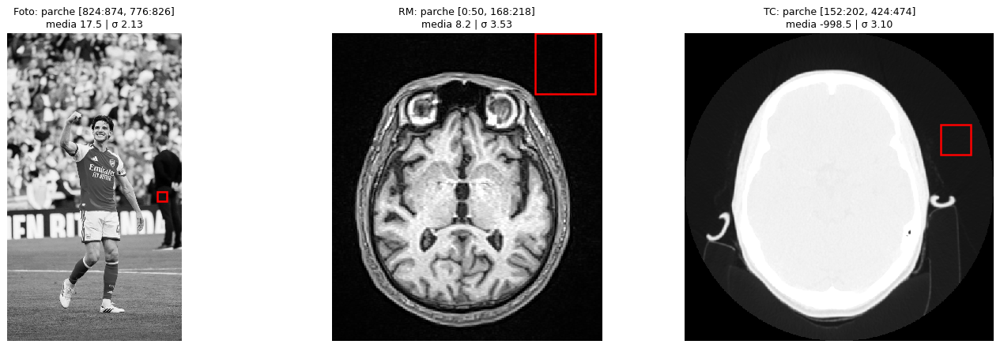

In [126]:
def buscar_parche(img, nombre, tam=TAM_PARCHE, paso=8):
    H, W = img.shape
    mejor = None
    for i in range(0, H - tam + 1, paso):
        for j in range(0, W - tam + 1, paso):
            b = img[i:i + tam, j:j + tam]
            if nombre == "Foto" and ((b <= 2).mean() > 0.01 or (b >= 253).mean() > 0.01):
                continue                                    # zona saturada
            if nombre == "TC":
                vecindad = img[max(i - 10, 0):i + tam + 10, max(j - 10, 0):j + tam + 10]
                if not (vecindad.min() > -1100 and vecindad.max() < -850):
                    continue                                # solo aire, lejos del relleno y de la cabeza
            if nombre == "RM" and (b == 0).mean() > 0.2:
                continue                                    # fondo enmascarado a 0 exacto: no tiene ruido
            # RM: el bloque más OSCURO es fondo sin tejido; foto y TC: el de menor varianza
            criterio = b.mean() if nombre == "RM" else b.var()
            if b.var() > 0 and (mejor is None or criterio < mejor[0]):
                mejor = (criterio, i, j)
    return mejor[1], mejor[2]

# La foto se mide en la versión ORIGINAL (sin reducir) en escala de gris
gris_original = np.floor(rgb_a_gris(foto_original))
img_ruido = {"Foto": gris_original, "RM": imgs["RM"], "TC": imgs["TC"]}
PARCHES = {n: buscar_parche(im, n) for n, im in img_ruido.items()}

def parche(img, nombre):
    i, j = PARCHES[nombre]
    return img[i:i + TAM_PARCHE, j:j + TAM_PARCHE]

fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, (n, im) in zip(ax, img_ruido.items()):
    i, j = PARCHES[n]
    if n == "TC":
        a.imshow(im, cmap="gray", vmin=-1100, vmax=100)
    else:
        a.imshow(im, cmap="gray", vmin=VENTANA[n][0], vmax=VENTANA[n][1])
    a.add_patch(Rectangle((j, i), TAM_PARCHE, TAM_PARCHE, ec="r", fc="none", lw=2))
    p = parche(im, n)
    a.set_title(f"{n}: parche [{i}:{i+TAM_PARCHE}, {j}:{j+TAM_PARCHE}]\nmedia {p.mean():.1f} | σ {p.std():.2f}"); a.axis("off")
plt.tight_layout(); plt.show()

**Ajuste y prueba.** Estimamos los parámetros con las fórmulas de cada distribución y aplicamos la **prueba de Kolmogorov-Smirnov**:
- **D** = máxima distancia entre la CDF de los datos y la del modelo. **El mejor ajuste es el de MENOR D.**
- **p-valor:** H₀ = "los datos siguen la distribución". **p > 0,05 → no se rechaza (sí la sigue); p ≤ 0,05 → se rechaza.**
- Para **Poisson** (discreta) usamos **chi-cuadrado** de bondad de ajuste en vez de KS.

Parámetros: Normal → μ = media, σ = desviación; Rayleigh → σ² = Σx² / 2n; Uniforme → mínimo y máximo; Poisson → λ = media (desplazando los datos para que empiecen en 0); Rician → ajuste por máxima verosimilitud.


=== Foto  (σ del parche = 2.13) ===
Distribución            D    p-valor
Normal             0.2069     0.0000   → se rechaza
Uniforme           0.4053     0.0000   → se rechaza
Poisson (chi²)        nan     0.0000   → se rechaza
Mejor ajuste por KS (menor D): Normal

=== RM  (σ del parche = 3.53) ===
Distribución            D    p-valor
Normal             0.1137     0.0000   → se rechaza
Uniforme           0.4092     0.0000   → se rechaza
Rayleigh           0.1537     0.0000   → se rechaza
Rician             0.1217     0.0000   → se rechaza
Poisson (chi²)        nan     0.0000   → se rechaza
Mejor ajuste por KS (menor D): Normal

=== TC  (σ del parche = 3.10) ===
Distribución            D    p-valor
Normal             0.1363     0.0000   → se rechaza
Uniforme           0.2968     0.0000   → se rechaza
Poisson (chi²)        nan     0.0000   → se rechaza
Mejor ajuste por KS (menor D): Normal


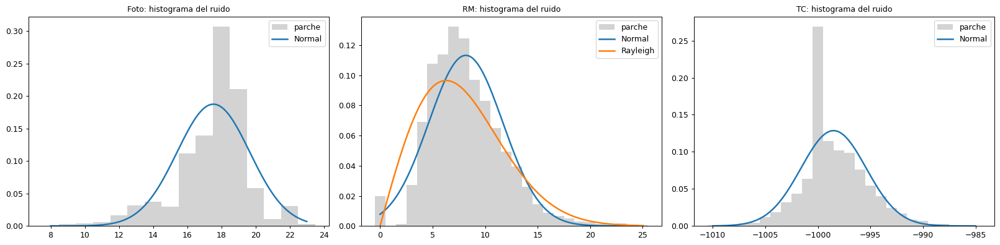

In [127]:
def probar_distribuciones(datos, nombre):
    x = datos.ravel().astype(float)
    n = len(x)
    filas = []
    mu, sd = x.mean(), x.std()
    filas.append(("Normal", *stats.kstest(x, stats.norm(mu, sd).cdf)))
    filas.append(("Uniforme", *stats.kstest(x, stats.uniform(x.min(), x.max() - x.min()).cdf)))
    if nombre == "RM":
        sigma = math.sqrt((x ** 2).sum() / (2 * n))
        filas.append(("Rayleigh", *stats.kstest(x, stats.rayleigh(0, sigma).cdf)))
        b, loc, esc = stats.rice.fit(x, floc=0)
        filas.append(("Rician", *stats.kstest(x, stats.rice(b, 0, esc).cdf)))
    # Poisson con chi-cuadrado
    z = (x - x.min()).astype(int)
    lam = z.mean()
    valores, observados = np.unique(z, return_counts=True)
    esperados = stats.poisson.pmf(valores, lam) * n
    ok = esperados >= 5
    chi2 = ((observados[ok] - esperados[ok]) ** 2 / esperados[ok]).sum()
    p_chi = stats.chi2.sf(chi2, ok.sum() - 2)
    filas.append(("Poisson (chi²)", float("nan"), p_chi))
    return filas, (mu, sd)

SIGMA_RUIDO = {}
fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
for a, (n, im) in zip(ax, img_ruido.items()):
    p = parche(im, n)
    SIGMA_RUIDO[n] = p.std()
    filas, (mu, sd) = probar_distribuciones(p, n)
    x = p.ravel()
    a.hist(x, bins=np.arange(x.min() - 0.5, x.max() + 1.5), density=True, color="lightgray", ec="gray", label="parche")
    t = np.linspace(x.min(), x.max(), 300)
    a.plot(t, stats.norm.pdf(t, mu, sd), lw=2, label="Normal")
    if n == "RM":
        s = math.sqrt((x.astype(float) ** 2).sum() / (2 * len(x)))
        a.plot(t, stats.rayleigh.pdf(t, 0, s), lw=2, label="Rayleigh")
    a.set_title(f"{n}: histograma del ruido"); a.legend()

    print(f"\n=== {n}  (σ del parche = {SIGMA_RUIDO[n]:.2f}) ===")
    print(f"{'Distribución':16s} {'D':>8s} {'p-valor':>10s}")
    for dn, D, pv in filas:
        print(f"{dn:16s} {D:8.4f} {pv:10.4f}   → {'no se rechaza' if pv > 0.05 else 'se rechaza'}")
    mejor = min([f for f in filas if not math.isnan(f[1])], key=lambda f: f[1])
    print(f"Mejor ajuste por KS (menor D): {mejor[0]}")
plt.tight_layout(); plt.show()

**Interpretación.** El mejor modelo es el de **menor D**, junto con el ajuste visual de la curva sobre el histograma. Con 2 500 píxeles de valores enteros, KS casi siempre da p ≈ 0: los muchos valores repetidos (empates) y el tamaño de la muestra hacen que detecte diferencias minúsculas. Por eso no basta con el p-valor: **comparamos D entre candidatas**. Con muestras pequeñas se usaría Shapiro-Wilk.

**Por qué importa:** cada filtro está pensado para un tipo de ruido. Usar el equivocado borra información útil.

In [128]:
# ¿La ecualización aumenta el ruido? Lo medimos en la zona homogénea (ambas en escala 0–255)
print(f"{'':5s} {'σ original':>12s} {'σ ecualizada':>14s}")
for n in ["RM", "TC"]:
    s0 = parche(a_8bits(imgs[n]), n).std(); s1 = parche(ecualizadas[n], n).std()
    print(f"{n:5s} {s0:12.2f} {s1:14.2f}   → x{s1 / max(s0, 1e-9):.1f}")
print("La ecualización estira los niveles más frecuentes: en el fondo, donde hay muchos píxeles parecidos, separa sus valores y amplifica el ruido.")

        σ original   σ ecualizada
RM            1.19          29.45   → x24.8
TC            0.42          15.83   → x37.4
La ecualización estira los niveles más frecuentes: en el fondo, donde hay muchos píxeles parecidos, separa sus valores y amplifica el ruido.


# KERNEL Y CONVOLUCIÓN
Todos los filtros usan esta función. Recorre la imagen con el kernel (cuadrado y de tamaño impar, para que tenga centro), multiplica elemento a elemento, suma y escribe el resultado **en una imagen nueva**, en la posición del centro.

- `recuperar=False`: no se calcula donde el kernel se sale de la imagen → se pierden ⌊n/2⌋ filas y columnas por lado. **Kernel 5×5 sobre 512×512 → 508×508.**
- `recuperar=True`: antes se **rellenan los bordes replicando el último valor**, y la salida conserva el tamaño original.
- El resultado se redondea con **piso (floor)**: con techo, 255,1 → 256 se saldría del rango.
- Un kernel de suavizado debe **sumar 1** para no cambiar el brillo.
- Para copiar una matriz se usa `.copy()`: `y = x` solo copia la referencia.

In [129]:
def rellenar_bordes(imagen, r):
    # Replica el último valor de cada borde r veces
    filas = [list(fila[:1]) * r + list(fila) + list(fila[-1:]) * r for fila in imagen]
    return [filas[0][:] for _ in range(r)] + filas + [filas[-1][:] for _ in range(r)]

def convolucion(imagen, kernel, recuperar=False, entero=True):
    imagen = np.asarray(imagen, dtype=float).tolist()
    kernel = np.asarray(kernel, dtype=float).tolist()
    n = len(kernel)
    assert n == len(kernel[0]) and n % 2 == 1, "El kernel debe ser cuadrado e impar"
    if recuperar:
        imagen = rellenar_bordes(imagen, n // 2)
    # convolución: el kernel se voltea (para kernels simétricos da lo mismo)
    k = [[kernel[n - 1 - u][n - 1 - v] for v in range(n)] for u in range(n)]
    filas, columnas = len(imagen), len(imagen[0])
    resultado = []
    for i in range(filas - n + 1):               # filas de la salida
        fila = []
        for j in range(columnas - n + 1):        # columnas de la salida
            suma = 0.0
            for u in range(n):                   # filas del kernel
                fila_img = imagen[i + u]
                fila_k = k[u]
                for v in range(n):               # columnas del kernel
                    suma += fila_img[j + v] * fila_k[v]
            fila.append(math.floor(suma) if entero else suma)
        resultado.append(fila)
    return np.array(resultado, dtype=float)

In [130]:
# Ejemplo pequeño para seguirlo a mano: media 3x3 sobre una matriz 5x5
A = [[10, 10, 10, 10, 10],
     [10, 50, 50, 50, 10],
     [10, 50, 200, 50, 10],
     [10, 50, 50, 50, 10],
     [10, 10, 10, 10, 10]]
media3 = [[1/9] * 3 for _ in range(3)]
print("Sin recuperar bordes (5x5 → 3x3):\n", convolucion(A, media3))
print("\nRecuperando bordes (5x5 → 5x5):\n", convolucion(A, media3, recuperar=True))
print(f"\nCentro: (8·50 + 200)/9 = {(8*50 + 200)/9:.2f} → piso → {math.floor((8*50 + 200)/9)}")

t0 = time.time()
media5 = [[1/25] * 5 for _ in range(5)]
print(f"\nTC {imgs['TC'].shape} con kernel 5x5 sin recuperar → {convolucion(imgs['TC'], media5).shape}  ({time.time() - t0:.1f} s)")

Sin recuperar bordes (5x5 → 3x3):
 [[44. 53. 44.]
 [53. 66. 53.]
 [44. 53. 44.]]

Recuperando bordes (5x5 → 5x5):
 [[14. 18. 23. 18. 14.]
 [18. 44. 53. 44. 18.]
 [23. 53. 66. 53. 23.]
 [18. 44. 53. 44. 18.]
 [14. 18. 23. 18. 14.]]

Centro: (8·50 + 200)/9 = 66.67 → piso → 66

TC (512, 512) con kernel 5x5 sin recuperar → (508, 508)  (0.6 s)


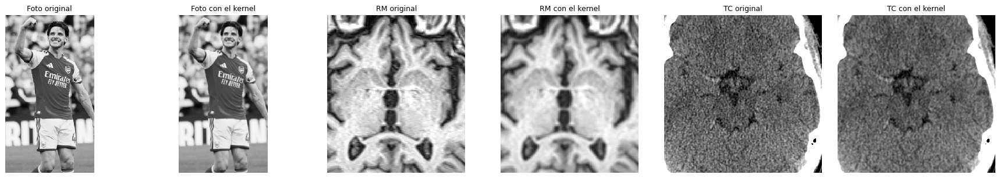

In [131]:
# Celda para probar un kernel en vivo (cambiar aquí)
kernel_prueba = [[1, 2, 1],
                 [2, 4, 2],
                 [1, 2, 1]]
kernel_prueba = (np.array(kernel_prueba) / np.sum(kernel_prueba)).tolist()
fig, ax = plt.subplots(1, 6, figsize=(20, 3.5))
for k, (n, im) in enumerate(imgs.items()):
    mostrar(ax[2 * k], recorte(im), n, f"{n} original")
    mostrar(ax[2 * k + 1], recorte(convolucion(im, kernel_prueba, recuperar=True)), n, f"{n} con el kernel")
plt.tight_layout(); plt.show()

# FILTROS DE PASO BAJO (suavizado)
Dejan pasar las **bajas frecuencias** (zonas lisas) y atenúan las **altas** (bordes y ruido). Siempre hay un compromiso: **más suavizado = menos ruido, pero menos detalle**. Como las subestructuras del cerebro son diminutas, ese compromiso decide el tamaño del kernel.

Para comparar con números y no solo a ojo medimos, en cada imagen filtrada:
- **Ruido restante:** σ en la zona homogénea, como % del original (menor = mejor).
- **Nitidez conservada:** magnitud de Sobel en los píxeles que en la original son borde fuerte (el 10 % más alto), como % del original (mayor = mejor).

In [132]:
SOBEL_X = [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]
SOBEL_Y = [[-1, -2, -1], [0, 0, 0], [1, 2, 1]]          # transpuesta de Sobel X

def magnitud_gradiente(img):
    gx = convolucion(img, SOBEL_X, recuperar=True, entero=False)
    gy = convolucion(img, SOBEL_Y, recuperar=True, entero=False)
    return np.sqrt(gx ** 2 + gy ** 2)

def kernel_media(n):
    return [[1 / n ** 2] * n for _ in range(n)]

# Zona inválida de la TC: el relleno fuera del círculo de escaneo y una franja de 6 píxeles a su alrededor
# (al suavizar, el -3024 del relleno "contamina" a sus vecinos y aparece un borde falso)
dentro = (imgs["TC"] > RELLENO_TC + 1).astype(float)
FUERA_TC = convolucion(dentro, kernel_media(13), recuperar=True, entero=False) < 0.999

BORDES = {}
for n, im in imgs.items():
    g = magnitud_gradiente(im)
    if n == "TC":
        g[FUERA_TC] = 0                                 # el borde del círculo de escaneo no cuenta
    BORDES[n] = (g >= np.percentile(g, 90), g)

# Parches de ruido en las imágenes que se filtran (la foto reducida tiene su propio parche)
PARCHES_FILTRO = {n: (PARCHES[n] if n != "Foto" else buscar_parche(imgs["Foto"], "Foto")) for n in imgs}
SIGMA_BASE = {n: imgs[n][PARCHES_FILTRO[n][0]:PARCHES_FILTRO[n][0] + TAM_PARCHE, PARCHES_FILTRO[n][1]:PARCHES_FILTRO[n][1] + TAM_PARCHE].std() for n in imgs}

def evaluar(filtrada, n):
    i, j = PARCHES_FILTRO[n]
    ruido = filtrada[i:i + TAM_PARCHE, j:j + TAM_PARCHE].std() / SIGMA_BASE[n] * 100
    mascara, g0 = BORDES[n]
    nitidez = magnitud_gradiente(filtrada)[mascara].mean() / g0[mascara].mean() * 100
    return ruido, nitidez

## Filtro de media
Todos los valores del kernel son 1/n². Reemplaza cada píxel por el promedio de su vecindario: reduce el ruido, pero trata igual un píxel de borde que uno de zona lisa, y difumina los bordes.

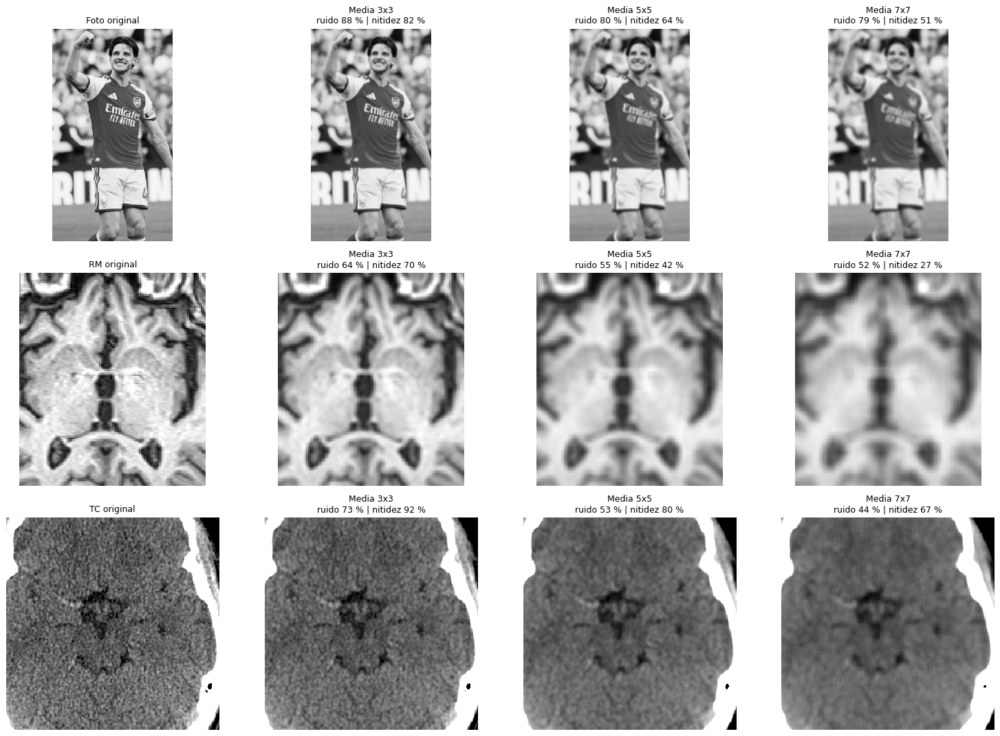

In [133]:
RES_MEDIA = {}
fig, ax = plt.subplots(3, 4, figsize=(17, 12))
for k, (n, im) in enumerate(imgs.items()):
    mostrar(ax[k, 0], recorte(im), n, f"{n} original")
    for c, t in enumerate([3, 5, 7]):
        f = convolucion(im, kernel_media(t), recuperar=True)
        RES_MEDIA[(n, t)] = evaluar(f, n)
        r, s = RES_MEDIA[(n, t)]
        mostrar(ax[k, c + 1], recorte(f), n, f"Media {t}x{t}\nruido {r:.0f} % | nitidez {s:.0f} %")
plt.tight_layout(); plt.show()

## Kernel gaussiano
$$G(x,y)=\frac{1}{2\pi\sigma^2}\,e^{-\frac{x^2+y^2}{2\sigma^2}}$$
El centro del kernel es (0, 0): en un 3×3 las coordenadas van de −1 a 1. Pesa más el centro y menos los vecinos lejanos, así que con el mismo tamaño difumina menos que la media. **Siempre se normaliza** (se divide por la suma) para que sume 1.

3x3, σ = 1, SIN normalizar:
    [0.0585, 0.0965, 0.0585]
    [0.0965, 0.1592, 0.0965]
    [0.0585, 0.0965, 0.0585]
Suma = 0.779 → la imagen se oscurece y pierde un 22 %

3x3, σ = 1, normalizado:
    [0.0751, 0.1238, 0.0751]
    [0.1238, 0.2042, 0.1238]
    [0.0751, 0.1238, 0.0751]

3x3, σ = 0.5, normalizado:
    [0.0113, 0.0838, 0.0113]
    [0.0838, 0.6193, 0.0838]
    [0.0113, 0.0838, 0.0113]

3x3, σ = 2, normalizado:
    [0.1019, 0.1154, 0.1019]
    [0.1154, 0.1308, 0.1154]
    [0.1019, 0.1154, 0.1019]


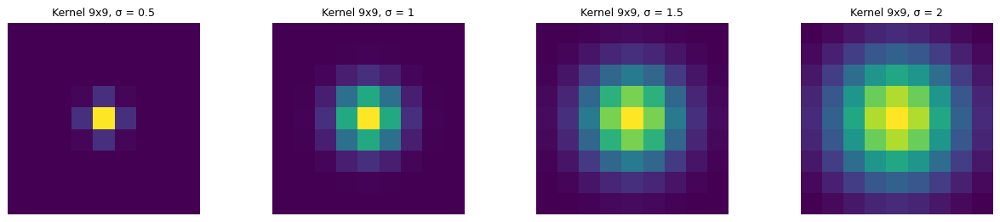

In [134]:
def crear_kernel_gaussiano(tamano, sigma):
    centro = tamano // 2
    kernel = []
    for i in range(tamano):
        fila = []
        for j in range(tamano):
            x, y = i - centro, j - centro
            fila.append((1 / (2 * math.pi * sigma ** 2)) * math.exp(-(x ** 2 + y ** 2) / (2 * sigma ** 2)))
        kernel.append(fila)
    return kernel

def crear_kernel_gaussiano_normalizado(tamano, sigma):
    kernel = crear_kernel_gaussiano(tamano, sigma)
    suma = sum(sum(fila) for fila in kernel)
    return [[v / suma for v in fila] for fila in kernel]

def imprimir(kernel):
    for fila in kernel:
        print("   ", [round(v, 4) for v in fila])

K = crear_kernel_gaussiano(3, 1)
print("3x3, σ = 1, SIN normalizar:"); imprimir(K)
s = sum(sum(f) for f in K)
print(f"Suma = {s:.3f} → la imagen se oscurece y pierde un {(1 - s) * 100:.0f} %\n")
print("3x3, σ = 1, normalizado:"); imprimir(crear_kernel_gaussiano_normalizado(3, 1))
for sg in [0.5, 2]:
    print(f"\n3x3, σ = {sg}, normalizado:"); imprimir(crear_kernel_gaussiano_normalizado(3, sg))

fig, ax = plt.subplots(1, 4, figsize=(14, 3))
for a, sg in zip(ax, [0.5, 1, 1.5, 2]):
    a.imshow(crear_kernel_gaussiano_normalizado(9, sg), cmap="viridis"); a.set_title(f"Kernel 9x9, σ = {sg}"); a.axis("off")
plt.tight_layout(); plt.show()

**σ pequeño** = campana alta: casi todo el peso en el centro, suaviza poco. **σ grande** = campana achatada: suaviza más, pero se pierden detalles y bordes. El kernel debe abarcar la campana (regla práctica: n ≈ 6σ + 1); si σ es grande y el kernel pequeño, la campana queda cortada y se parece a una media.

**Comparación de parámetros: 4 tamaños × 4 valores de σ en las tres imágenes.**

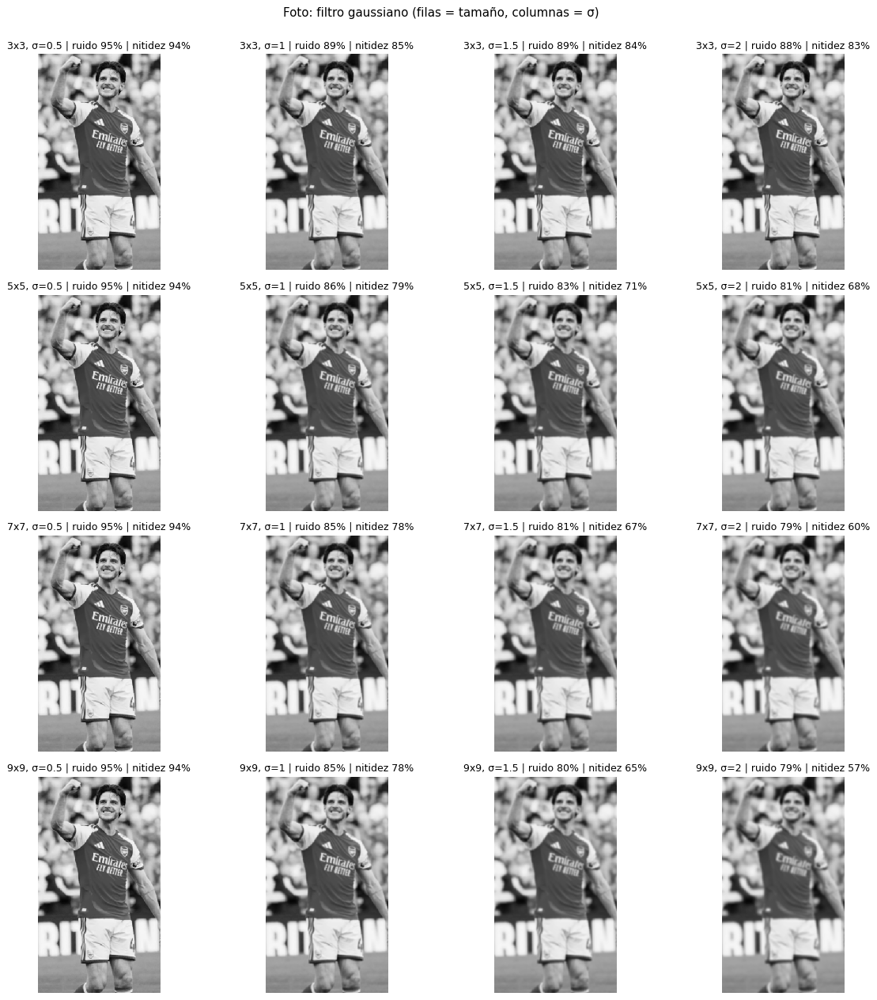

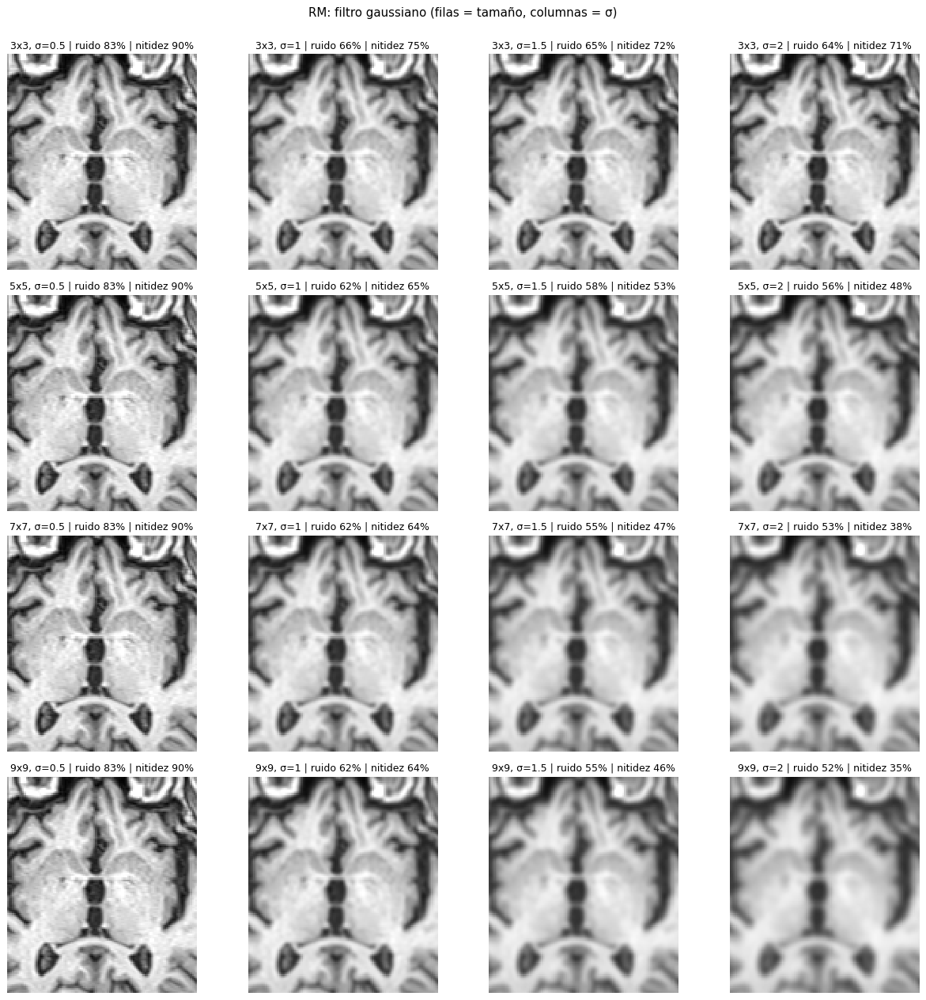

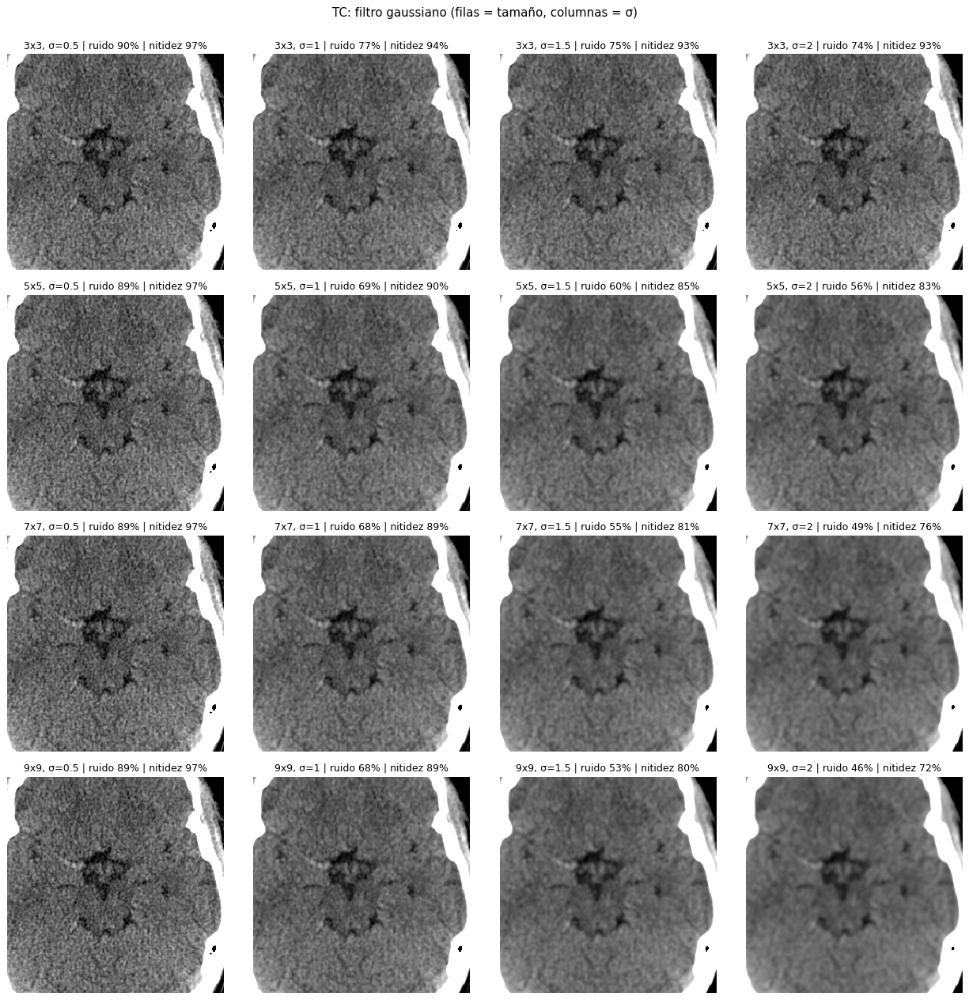

Tiempo total: 76 s


In [135]:
TAMANOS = [3, 5, 7, 9]
SIGMAS = [0.5, 1, 1.5, 2]
RES_GAUSS = {}
t0 = time.time()
for n, im in imgs.items():
    fig, ax = plt.subplots(len(TAMANOS), len(SIGMAS), figsize=(14, 14))
    for a_, t in enumerate(TAMANOS):
        for b_, sg in enumerate(SIGMAS):
            f = convolucion(im, crear_kernel_gaussiano_normalizado(t, sg), recuperar=True)
            RES_GAUSS[(n, t, sg)] = evaluar(f, n)
            r, nt = RES_GAUSS[(n, t, sg)]
            mostrar(ax[a_, b_], recorte(f), n, f"{t}x{t}, σ={sg} | ruido {r:.0f}% | nitidez {nt:.0f}%")
    fig.suptitle(f"{n}: filtro gaussiano (filas = tamaño, columnas = σ)", y=1.0)
    plt.tight_layout(); plt.show()
print(f"Tiempo total: {time.time() - t0:.0f} s")

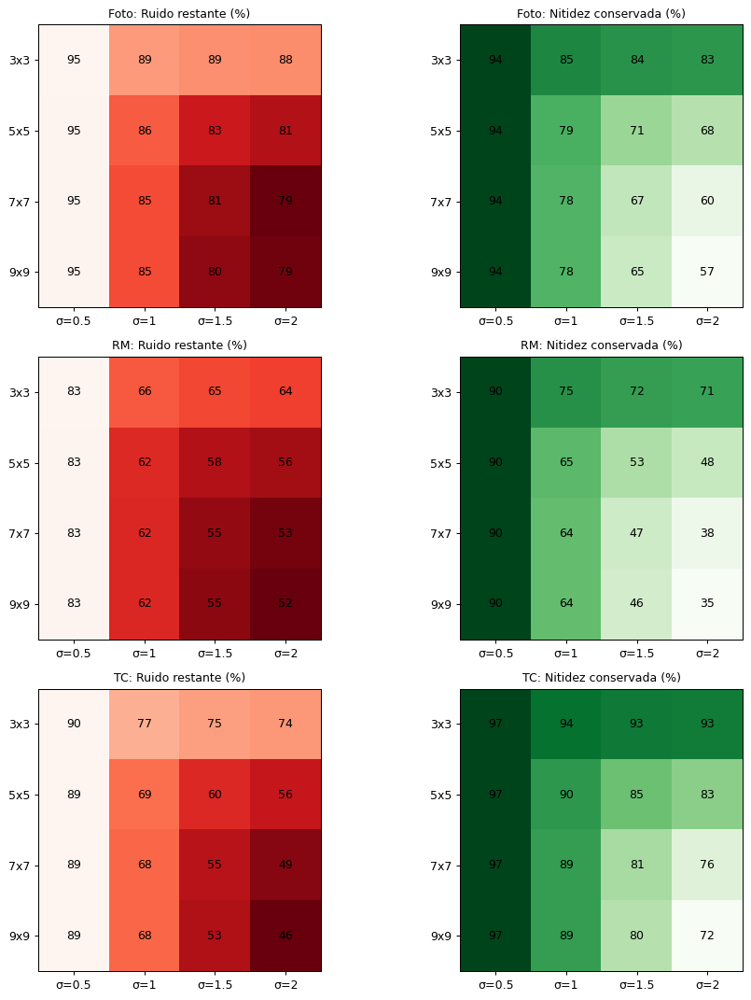

In [136]:
fig, ax = plt.subplots(3, 2, figsize=(11, 12))
for k, n in enumerate(imgs):
    for c, (idx, titulo, cmap) in enumerate([(0, "Ruido restante (%)", "Reds_r"), (1, "Nitidez conservada (%)", "Greens")]):
        M = np.array([[RES_GAUSS[(n, t, sg)][idx] for sg in SIGMAS] for t in TAMANOS])
        a = ax[k, c]; a.imshow(M, cmap=cmap)
        for i in range(len(TAMANOS)):
            for j in range(len(SIGMAS)):
                a.text(j, i, f"{M[i, j]:.0f}", ha="center", va="center")
        a.set_xticks(range(len(SIGMAS))); a.set_xticklabels([f"σ={sg}" for sg in SIGMAS])
        a.set_yticks(range(len(TAMANOS))); a.set_yticklabels([f"{t}x{t}" for t in TAMANOS])
        a.set_title(f"{n}: {titulo}")
plt.tight_layout(); plt.show()

**Cómo leer las tablas:** al bajar por las filas (más tamaño) o ir a la derecha (más σ) baja el ruido y también la nitidez. Con σ = 0,5 el tamaño casi no importa, porque la campana ya es angosta en 3×3. Con σ = 2, un 3×3 corta la campana y se comporta casi como una media. Escogemos la combinación que quita buena parte del ruido sin perder demasiada nitidez, que en las tres imágenes queda en kernels pequeños (5×5) con σ ≈ 1.

## Filtro de mediana
**No es una convolución:** no hay kernel de pesos. Para cada píxel se ordenan los valores del vecindario y se toma el del medio, así que es **no lineal**. Un valor atípico nunca llega a la salida porque queda en un extremo del ordenamiento, y los bordes se conservan mejor que con la media. Usamos ventanas pequeñas porque las subestructuras son diminutas.

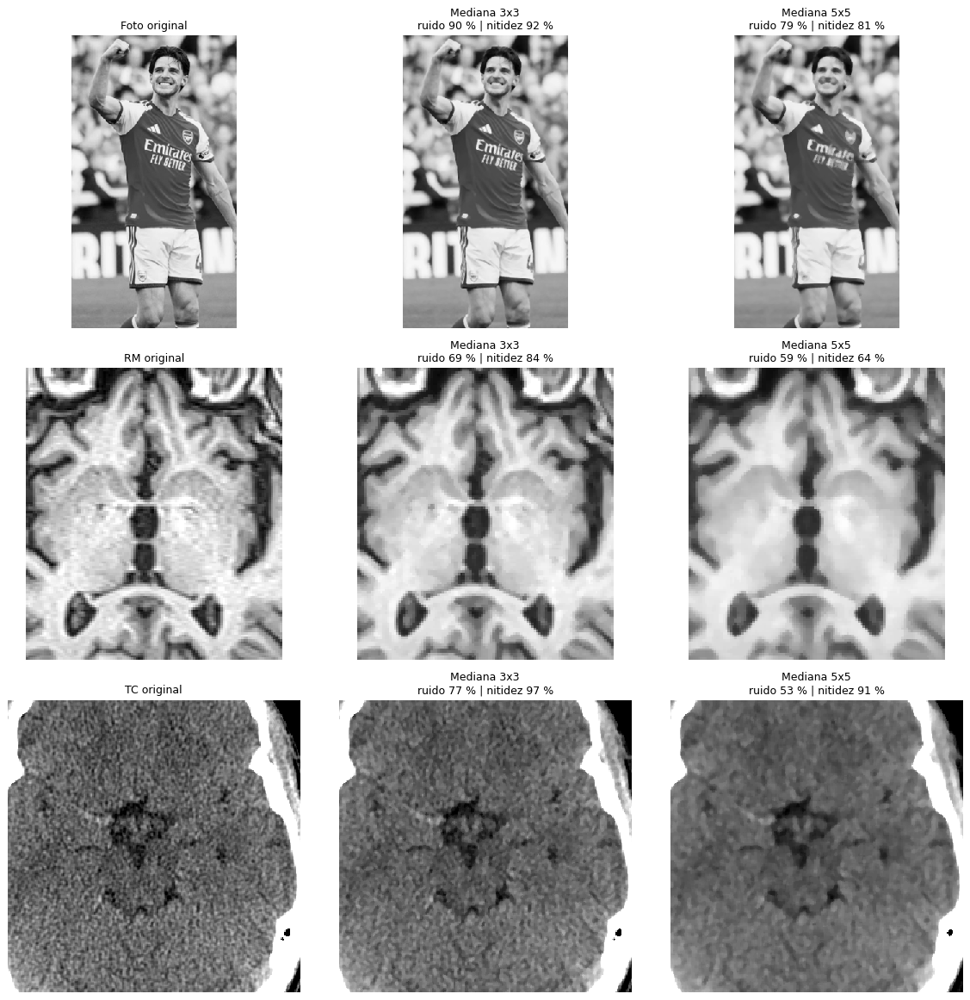

In [137]:
def mediana(imagen, n, recuperar=True):
    img = np.asarray(imagen, dtype=float).tolist()
    if recuperar:
        img = rellenar_bordes(img, n // 2)
    filas, columnas = len(img), len(img[0])
    medio = (n * n) // 2
    resultado = []
    for i in range(filas - n + 1):
        fila = []
        for j in range(columnas - n + 1):
            vecinos = []
            for u in range(n):
                vecinos.extend(img[i + u][j:j + n])
            vecinos.sort()
            fila.append(vecinos[medio])
        resultado.append(fila)
    return np.array(resultado, dtype=float)

RES_MEDIANA = {}
fig, ax = plt.subplots(3, 3, figsize=(13, 13))
for k, (n, im) in enumerate(imgs.items()):
    mostrar(ax[k, 0], recorte(im), n, f"{n} original")
    for c, t in enumerate([3, 5]):
        f = mediana(im, t)
        RES_MEDIANA[(n, t)] = evaluar(f, n)
        r, s = RES_MEDIANA[(n, t)]
        mostrar(ax[k, c + 1], recorte(f), n, f"Mediana {t}x{t}\nruido {r:.0f} % | nitidez {s:.0f} %")
plt.tight_layout(); plt.show()

**Prueba con ruido sal y pimienta en la foto:** le agregamos un 5 % de píxeles en 0 o 255 y comparamos los tres filtros contra la foto limpia con el **PSNR** (en dB; mayor = más parecida a la original).

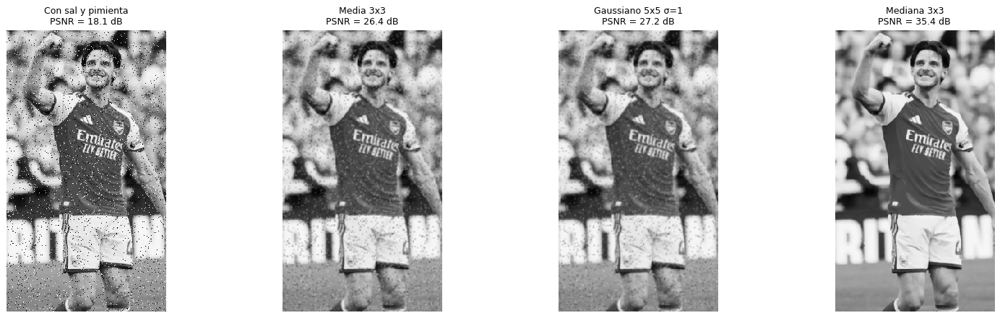

In [138]:
def psnr(a, b):
    return 10 * math.log10(255 ** 2 / np.mean((a - b) ** 2))

limpia = imgs["Foto"]
sp = limpia.copy()                        # .copy(): con "sp = limpia" modificaríamos la original
azar = np.random.default_rng(0).random(sp.shape)
sp[azar < 0.025] = 0
sp[azar > 0.975] = 255
candidatos = {"Con sal y pimienta": sp,
              "Media 3x3": convolucion(sp, kernel_media(3), recuperar=True),
              "Gaussiano 5x5 σ=1": convolucion(sp, crear_kernel_gaussiano_normalizado(5, 1), recuperar=True),
              "Mediana 3x3": mediana(sp, 3)}
fig, ax = plt.subplots(1, 4, figsize=(18, 5))
for a, (nombre, im) in zip(ax, candidatos.items()):
    mostrar(a, recorte(im), "Foto", f"{nombre}\nPSNR = {psnr(im, limpia):.1f} dB")
plt.tight_layout(); plt.show()

In [139]:
# Resumen de paso bajo por imagen: buscamos poco ruido restante con alta nitidez conservada
for n in imgs:
    filas = [(f"Media {t}x{t}", *RES_MEDIA[(n, t)]) for t in [3, 5, 7]]
    filas += [(f"Gauss {t}x{t} σ={sg}", *RES_GAUSS[(n, t, sg)]) for t in TAMANOS for sg in SIGMAS]
    filas += [(f"Mediana {t}x{t}", *RES_MEDIANA[(n, t)]) for t in [3, 5]]
    print(f"\n=== {n} ===  (ordenado de menos a más ruido restante)")
    print(f"{'Filtro':20s} {'ruido %':>8s} {'nitidez %':>10s}")
    for nombre, r, s in sorted(filas, key=lambda f: f[1]):
        print(f"{nombre:20s} {r:8.0f} {s:10.0f}")


=== Foto ===  (ordenado de menos a más ruido restante)
Filtro                ruido %  nitidez %
Gauss 7x7 σ=2              79         60
Gauss 9x9 σ=2              79         57
Media 7x7                  79         51
Mediana 5x5                79         81
Media 5x5                  80         64
Gauss 9x9 σ=1.5            80         65
Gauss 7x7 σ=1.5            81         67
Gauss 5x5 σ=2              81         68
Gauss 5x5 σ=1.5            83         71
Gauss 9x9 σ=1              85         78
Gauss 7x7 σ=1              85         78
Gauss 5x5 σ=1              86         79
Media 3x3                  88         82
Gauss 3x3 σ=2              88         83
Gauss 3x3 σ=1.5            89         84
Gauss 3x3 σ=1              89         85
Mediana 3x3                90         92
Gauss 5x5 σ=0.5            95         94
Gauss 7x7 σ=0.5            95         94
Gauss 9x9 σ=0.5            95         94
Gauss 3x3 σ=0.5            95         94

=== RM ===  (ordenado de menos a más ruid

# FILTRO SOBEL
Un borde es un cambio brusco de intensidad (alta frecuencia), y lo detectamos con derivadas. **Sobel (primera derivada):** Gx = [[−1,0,1],[−2,0,2],[−1,0,1]] detecta cambios horizontales (bordes verticales) y Gy (su transpuesta) cambios verticales. Se aplican **por separado** sobre la imagen **ya suavizada** y se combinan en:
- **Magnitud** = √(Gx² + Gy²): qué tan fuerte es el borde.
- **Dirección** = arctan(Gy / Gx): hacia dónde crece la intensidad. Usamos `math.atan2`, que no falla cuando Gx = 0.

Las derivadas amplifican el ruido (el ruido son cambios bruscos de píxel a píxel). Por eso **primero se suaviza**; abajo lo comprobamos con y sin suavizado.

In [140]:
SUAVIZADO = {"Foto": (5, 1.0), "RM": (5, 1.0), "TC": (5, 1.0)}    # (tamaño, σ) escogidos en paso bajo
suaves = {n: convolucion(im, crear_kernel_gaussiano_normalizado(*SUAVIZADO[n]), recuperar=True) for n, im in imgs.items()}

def sobel(img):
    gx = convolucion(img, SOBEL_X, recuperar=True, entero=False)
    gy = convolucion(img, SOBEL_Y, recuperar=True, entero=False)
    magnitud = np.sqrt(gx ** 2 + gy ** 2)                    # sin recortar a 255: se escala solo al mostrar
    direccion = np.array([[math.degrees(math.atan2(y, x)) for x, y in zip(fx, fy)] for fx, fy in zip(gx, gy)])
    return gx, gy, magnitud, direccion

for n, im in imgs.items():
    fig, ax = plt.subplots(2, 5, figsize=(21, 8.5))
    for f, (etiqueta, base) in enumerate([("sin suavizar", im), (f"suavizada (gauss {SUAVIZADO[n][0]}x{SUAVIZADO[n][0]}, σ={SUAVIZADO[n][1]})", suaves[n])]):
        gx, gy, mag, ang = sobel(base)
        if n == "TC":
            gx[FUERA_TC] = gy[FUERA_TC] = mag[FUERA_TC] = 0
        lim = np.percentile(np.abs(gx), 99)
        mostrar(ax[f, 0], base, n, f"{n} {etiqueta}")
        ax[f, 1].imshow(gx, cmap="gray", vmin=-lim, vmax=lim); ax[f, 1].set_title("Gx (bordes verticales)")
        ax[f, 2].imshow(gy, cmap="gray", vmin=-lim, vmax=lim); ax[f, 2].set_title("Gy (bordes horizontales)")
        ax[f, 3].imshow(mag, cmap="gray", vmax=np.percentile(mag, 95)); ax[f, 3].set_title("Magnitud √(Gx² + Gy²)")
        fuerte = mag > np.percentile(mag, 85)
        ax[f, 4].imshow(np.where(fuerte, ang, np.nan), cmap="hsv", vmin=-180, vmax=180)
        ax[f, 4].set_facecolor("k"); ax[f, 4].set_title("Dirección (°), solo bordes fuertes")
        for a in ax[f]: a.axis("off")
        i, j = PARCHES_FILTRO[n]
        print(f"{n} {etiqueta:40s}: σ de la magnitud en la zona homogénea = {mag[i:i+TAM_PARCHE, j:j+TAM_PARCHE].std():.2f}")
    plt.tight_layout(); plt.show()

Output hidden; open in https://colab.research.google.com to view.

**Cómo leer la dirección:** el color es el ángulo del gradiente (de −180° a 180°), es decir, hacia dónde aumenta la intensidad. A ambos lados de una misma línea los colores son opuestos. En zonas lisas el gradiente es casi 0 y su ángulo es aleatorio: por eso la imagen de dirección "se ve rara" y solo la mostramos donde hay borde fuerte.

# FILTRO LAPLACIANO
**Segunda derivada** (por serie de Taylor, componentes [1, −2, 1] en horizontal y vertical). Responde a los cambios en todas las direcciones a la vez; el borde está donde la respuesta **cruza por cero**. Las tres versiones vistas en clase **suman 0**, así que en una zona plana la respuesta es 0:
- 4 vecinos: [[0,1,0],[1,−4,1],[0,1,0]]
- 8 vecinos: centro −8 y el resto 1
- Con parámetro α: [[α, 1−α, α],[1−α, −4, 1−α],[α, 1−α, α]] / (1+α)

4 vecinos  suma = 0.0
8 vecinos  suma = 0.0
α = 0,5    suma = 0.0


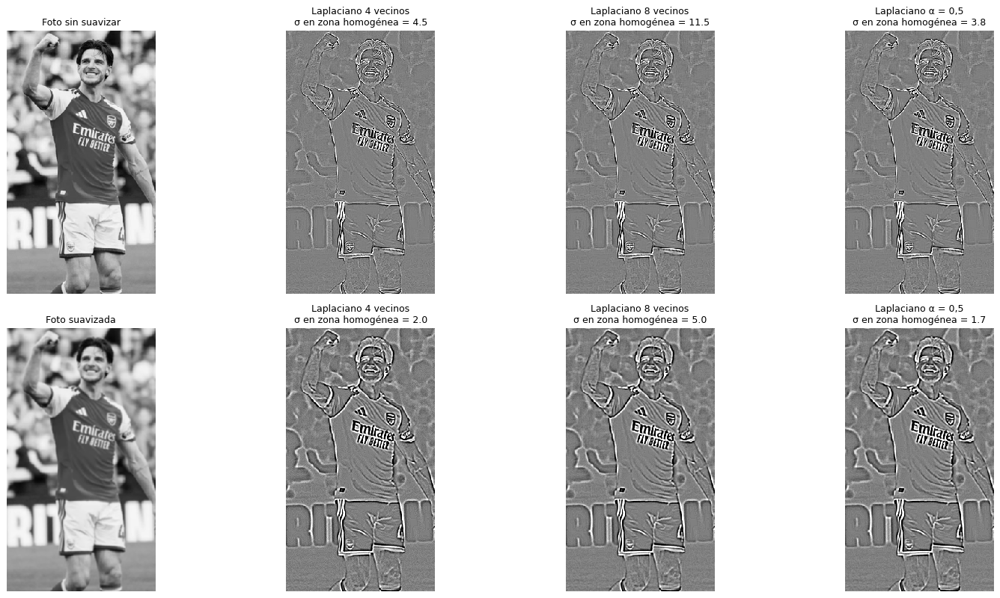

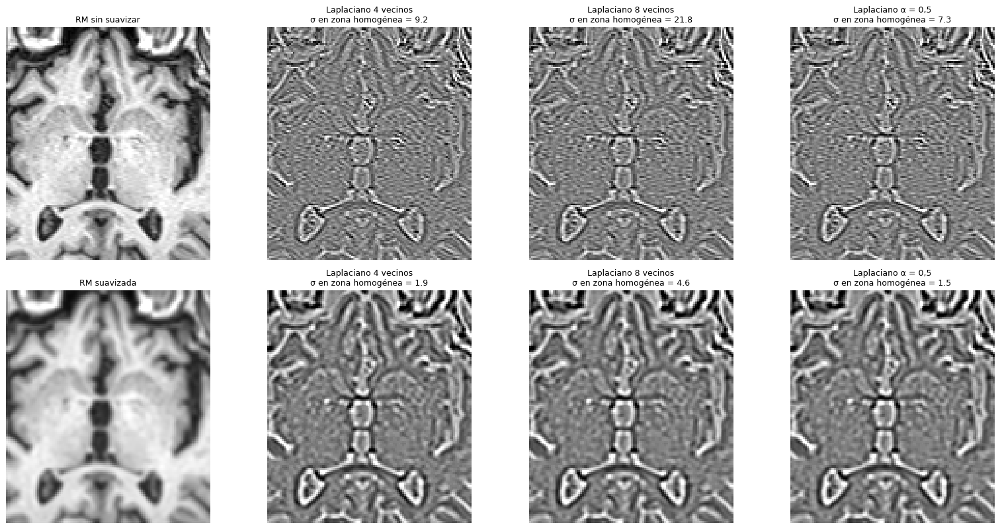

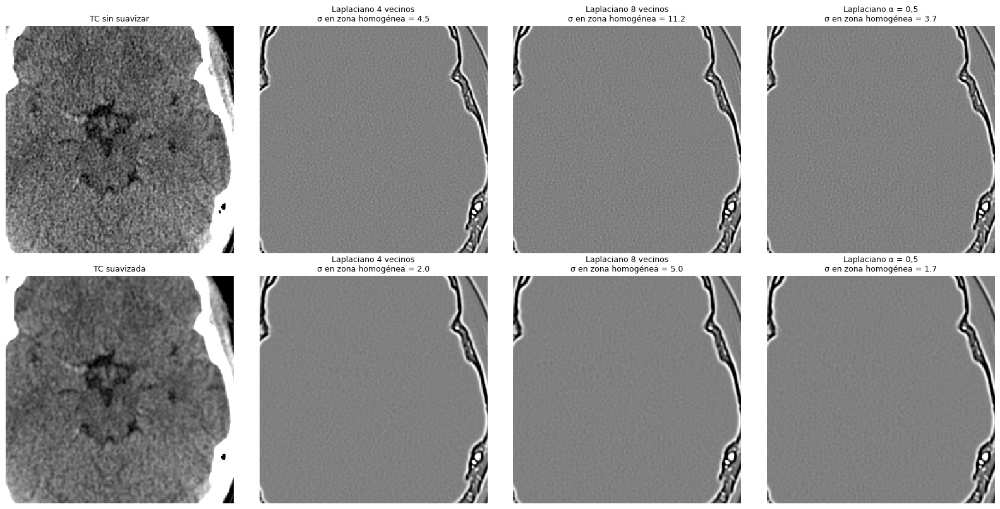

In [141]:
LAP_4 = [[0, 1, 0], [1, -4, 1], [0, 1, 0]]
LAP_8 = [[1, 1, 1], [1, -8, 1], [1, 1, 1]]
def lap_alfa(a):
    return [[a / (1 + a), (1 - a) / (1 + a), a / (1 + a)],
            [(1 - a) / (1 + a), -4 / (1 + a), (1 - a) / (1 + a)],
            [a / (1 + a), (1 - a) / (1 + a), a / (1 + a)]]

LAPLACIANOS = {"4 vecinos": LAP_4, "8 vecinos": LAP_8, "α = 0,5": lap_alfa(0.5)}
for nombre, K in LAPLACIANOS.items():
    print(f"{nombre:10s} suma = {sum(sum(f) for f in K):.1f}")

for n, im in imgs.items():
    fig, ax = plt.subplots(2, 4, figsize=(18, 9))
    for f, (etiqueta, base) in enumerate([("sin suavizar", im), ("suavizada", suaves[n])]):
        mostrar(ax[f, 0], recorte(base), n, f"{n} {etiqueta}")
        for c, (nombre, K) in enumerate(LAPLACIANOS.items()):
            L = convolucion(base, K, recuperar=True, entero=False)
            if n == "TC": L[FUERA_TC] = 0
            lim = np.percentile(np.abs(L), 99)
            i, j = PARCHES_FILTRO[n]
            ax[f, c + 1].imshow(recorte(L), cmap="gray", vmin=-lim, vmax=lim)
            ax[f, c + 1].set_title(f"Laplaciano {nombre}\nσ en zona homogénea = {L[i:i+TAM_PARCHE, j:j+TAM_PARCHE].std():.1f}")
            ax[f, c + 1].axis("off")
    plt.tight_layout(); plt.show()

**Qué muestra:** sin suavizar, el Laplaciano responde sobre todo al ruido (σ alta en la zona homogénea) y los bordes se pierden entre el granulado. Después del gaussiano la respuesta en zonas lisas baja mucho y quedan los contornos. Por eso tanto Sobel como el Laplaciano se aplican siempre sobre la imagen suavizada.

# OPERADORES BASADOS EN LA VARIANZA
La **varianza local** (en una ventana que se desliza) mide qué tan homogénea es cada zona: baja en tejido uniforme, alta en bordes y texturas. La calculamos con nuestra convolución: **Var = E[x²] − (E[x])²**, donde ambas esperanzas son un filtro de media.

- **Filtro de uniformidad:** R = 1 − 1 / (1 + Var(x)). Es 0 en una zona perfectamente uniforme y tiende a 1 cuando la varianza crece.
- **Filtro de Lee (adaptativo):** x̂ = μ_local + k·(x − μ_local), con k = máx(0, (σ²_local − σ²_ruido) / σ²_local). En zonas uniformes k ≈ 0 y suaviza fuerte; en bordes k ≈ 1 y conserva el píxel. La σ² del ruido sale de la **sección de ruido**.
- **Filtro de Frost:** también adaptativo, para ruido *speckle* (multiplicativo) de radar y ultrasonido. No lo aplicamos: nuestro ruido no es multiplicativo y en la TC la media local puede ser negativa (HU).

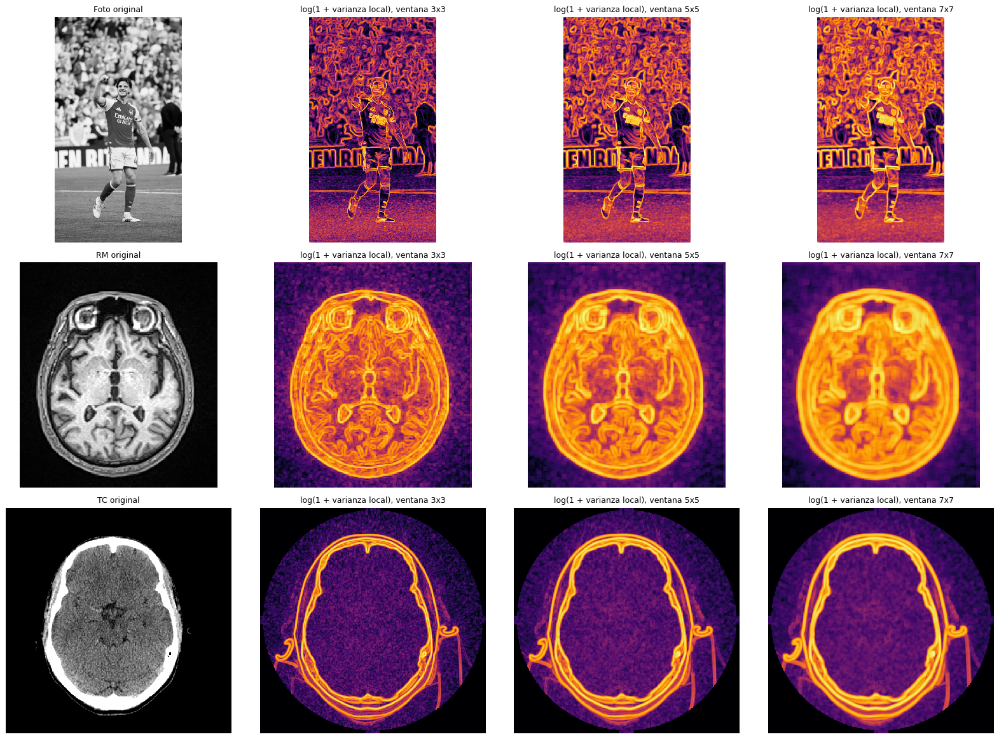

In [142]:
def media_y_varianza_local(img, n):
    m = convolucion(img, kernel_media(n), recuperar=True, entero=False)
    m2 = convolucion(img ** 2, kernel_media(n), recuperar=True, entero=False)
    return m, np.maximum(m2 - m ** 2, 0)

def uniformidad(var):
    return 1 - 1 / (1 + var)

fig, ax = plt.subplots(3, 4, figsize=(18, 13))
for k, (n, im) in enumerate(imgs.items()):
    mostrar(ax[k, 0], im, n, f"{n} original")
    for c, t in enumerate([3, 5, 7]):
        _, v = media_y_varianza_local(im, t)
        if n == "TC": v[FUERA_TC] = 0
        ax[k, c + 1].imshow(np.log1p(v), cmap="inferno"); ax[k, c + 1].set_title(f"log(1 + varianza local), ventana {t}x{t}"); ax[k, c + 1].axis("off")
plt.tight_layout(); plt.show()

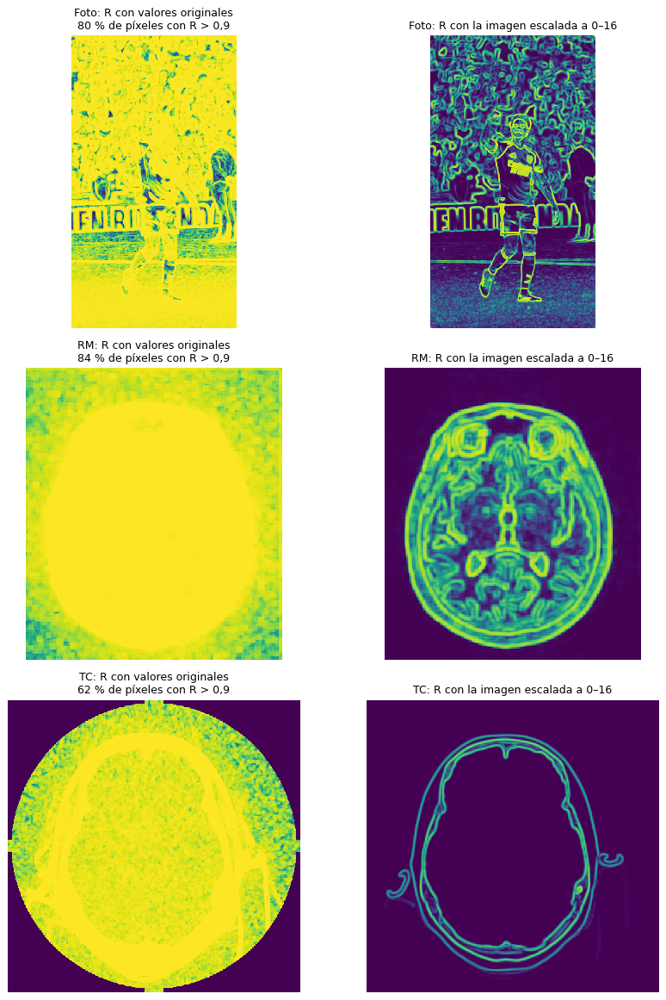

In [143]:
# Uniformidad R: con los valores originales vs. con la imagen normalizada
fig, ax = plt.subplots(3, 2, figsize=(10, 13))
for k, (n, im) in enumerate(imgs.items()):
    _, v = media_y_varianza_local(im, 5)
    normal = (im - im.min()) / (im.max() - im.min()) * 16          # escala pequeña (0–16)
    _, vn = media_y_varianza_local(normal, 5)
    R1, R2 = uniformidad(v), uniformidad(vn)
    if n == "TC":
        R1[FUERA_TC] = 0; R2[FUERA_TC] = 0
    ax[k, 0].imshow(R1, cmap="viridis", vmin=0, vmax=1); ax[k, 0].set_title(f"{n}: R con valores originales\n{(R1 > 0.9).mean()*100:.0f} % de píxeles con R > 0,9")
    ax[k, 1].imshow(R2, cmap="viridis", vmin=0, vmax=1); ax[k, 1].set_title(f"{n}: R con la imagen escalada a 0–16")
    for a in ax[k]: a.axis("off")
plt.tight_layout(); plt.show()

**Tropiezo con la uniformidad:** con los valores originales, la varianza del propio ruido ya es grande, así que R ≈ 1 casi en toda la imagen y no distingue nada. R se satura y **depende de la escala**: hay que normalizar la imagen antes de aplicarla. Escalada a un rango pequeño, R separa las zonas uniformes de los bordes.

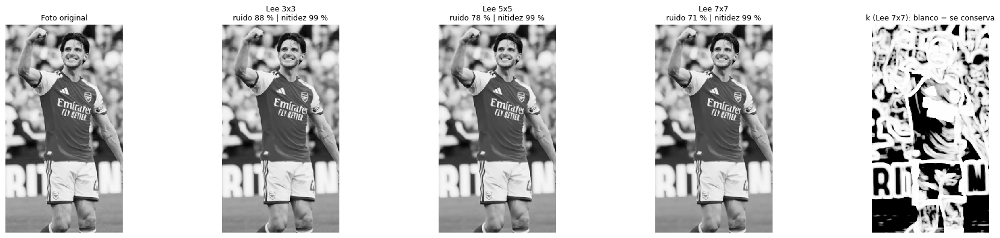

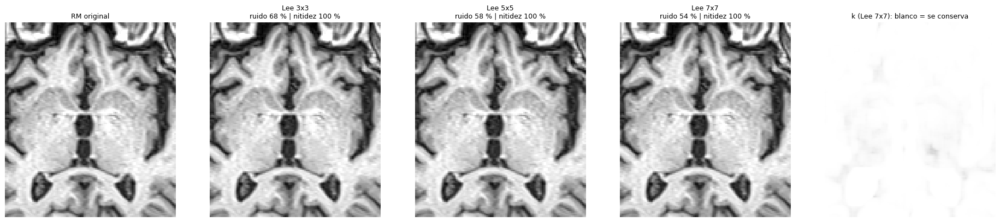

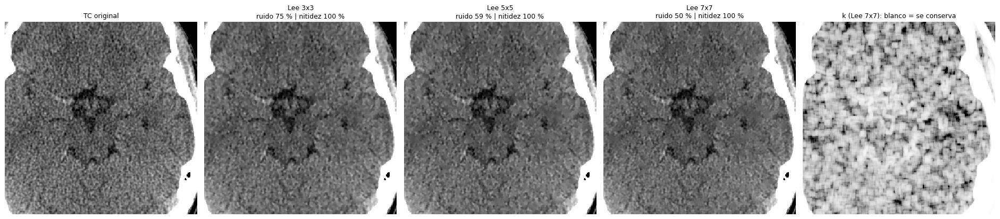

      Filtro              ruido %  nitidez %
Foto  Gauss 5x5 σ=1            86         79
Foto  Mediana 3x3              90         92
Foto  Lee 5x5                  78         99
Foto  Lee 7x7                  71         99
RM    Gauss 5x5 σ=1            62         65
RM    Mediana 3x3              69         84
RM    Lee 5x5                  58        100
RM    Lee 7x7                  54        100
TC    Gauss 5x5 σ=1            69         90
TC    Mediana 3x3              77         97
TC    Lee 5x5                  59        100
TC    Lee 7x7                  50        100


In [144]:
def filtro_lee(img, n, var_ruido):
    m, v = media_y_varianza_local(img, n)
    k = np.maximum(0, (v - var_ruido) / np.maximum(v, 1e-12))
    return np.floor(m + k * (img - m)), k

RES_LEE = {}
for n, im in imgs.items():
    fig, ax = plt.subplots(1, 5, figsize=(21, 4.5))
    mostrar(ax[0], recorte(im), n, f"{n} original")
    for c, t in enumerate([3, 5, 7]):
        f, kmap = filtro_lee(im, t, SIGMA_BASE[n] ** 2)
        RES_LEE[(n, t)] = evaluar(f, n)
        r, s = RES_LEE[(n, t)]
        mostrar(ax[c + 1], recorte(f), n, f"Lee {t}x{t}\nruido {r:.0f} % | nitidez {s:.0f} %")
    ax[4].imshow(recorte(kmap), cmap="gray", vmin=0, vmax=1); ax[4].set_title("k (Lee 7x7): blanco = se conserva"); ax[4].axis("off")
    plt.tight_layout(); plt.show()

print(f"{'':5s} {'Filtro':18s} {'ruido %':>8s} {'nitidez %':>10s}")
for n in imgs:
    for nombre, (r, s) in [("Gauss 5x5 σ=1", RES_GAUSS[(n, 5, 1)]), ("Mediana 3x3", RES_MEDIANA[(n, 3)]),
                           ("Lee 5x5", RES_LEE[(n, 5)]), ("Lee 7x7", RES_LEE[(n, 7)])]:
        print(f"{n:5s} {nombre:18s} {r:8.0f} {s:10.0f}")

**Qué muestra el mapa k:** en blanco (k ≈ 1) Lee conserva el píxel original porque la varianza local es mucho mayor que la del ruido: bordes y estructuras. En negro (k ≈ 0) reemplaza el píxel por el promedio local: zonas uniformes.

**Tropiezo en la TC:** la σ del ruido la medimos en el aire, pero dentro del cerebro el ruido es mayor (los rayos X atraviesan hueso y tejido antes de llegar al detector). Por eso Lee interpreta parte del ruido del tejido como "estructura" y suaviza menos el cerebro de lo esperado. Una alternativa es medir la σ del ruido en una zona homogénea del tejido.

# PIPELINE FINAL Y CONCLUSIONES

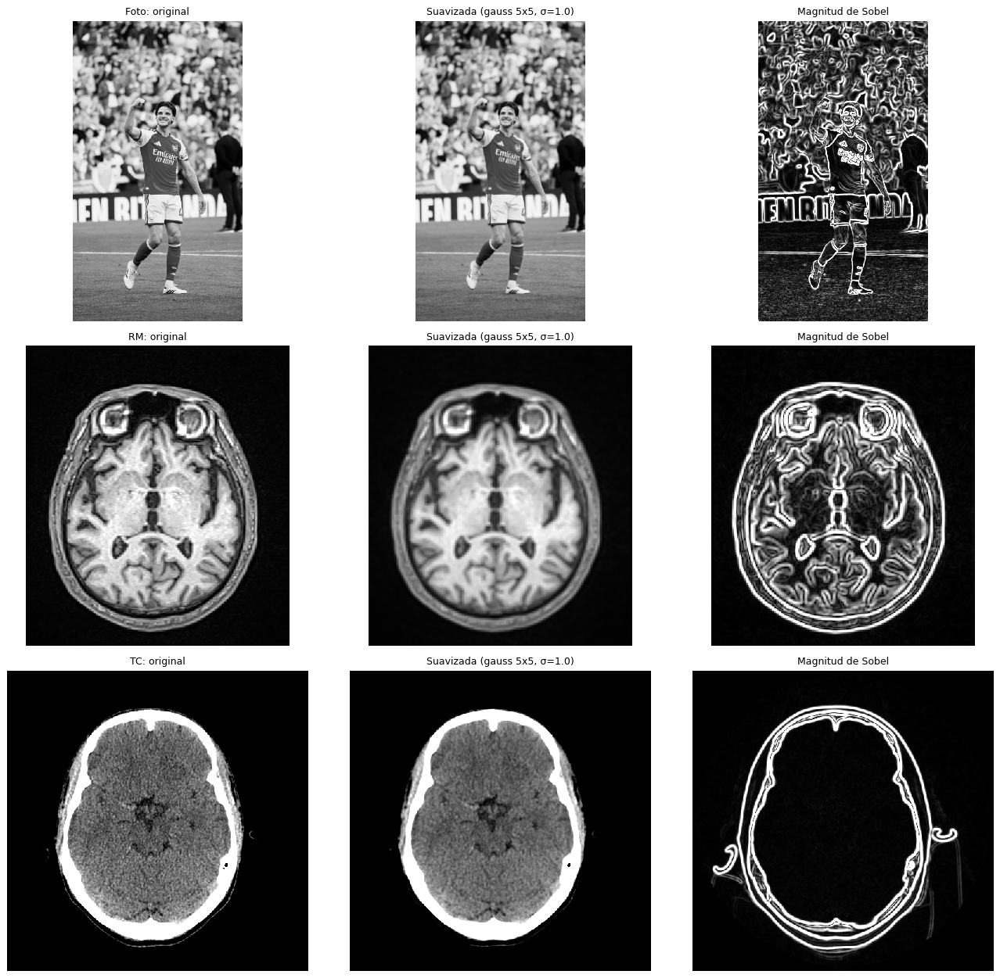

In [145]:
fig, ax = plt.subplots(3, 3, figsize=(15, 14))
for k, (n, im) in enumerate(imgs.items()):
    _, _, mag, _ = sobel(suaves[n])
    if n == "TC": mag[FUERA_TC] = 0
    mostrar(ax[k, 0], im, n, f"{n}: original")
    mostrar(ax[k, 1], suaves[n], n, f"Suavizada (gauss {SUAVIZADO[n][0]}x{SUAVIZADO[n][0]}, σ={SUAVIZADO[n][1]})")
    ax[k, 2].imshow(mag, cmap="gray", vmax=np.percentile(mag, 95)); ax[k, 2].set_title("Magnitud de Sobel"); ax[k, 2].axis("off")
plt.tight_layout(); plt.show()

**Conclusiones** _(revisar con los números de esta ejecución antes del control)_

1. **Cada modalidad tiene valores y ruido distintos.** La foto tiene 256 niveles y ruido de sensor aproximadamente gaussiano; la RM tiene 16 bits y en el fondo ruido tipo Rayleigh (magnitud de dos señales); la TC está en HU, con un relleno de −3024 fuera del círculo de escaneo que hay que excluir.
2. **El tipo de ruido decide el filtro.** El gaussiano es adecuado para ruido aditivo gaussiano; la mediana elimina impulsos (sal y pimienta) y valores atípicos sin difuminar tanto los bordes; los filtros adaptativos (Lee) suavizan solo donde la varianza local es parecida a la del ruido.
3. **Tamaño y σ:** como las estructuras del sistema límbico son pequeñas, preferimos kernels pequeños (5×5) con σ ≈ 1. Con kernels grandes o σ grande el ruido baja más, pero se pierde nitidez en los bordes.
4. **Bordes:** Sobel y el Laplaciano sin suavizar responden sobre todo al ruido; después del gaussiano quedan los contornos. Por eso siempre se suaviza primero.
5. **Ecualización:** mejora el contraste visual, pero amplifica el ruido en las zonas homogéneas (lo medimos), así que no conviene aplicarla antes de detectar bordes.
6. **Tropiezos:** KS da p ≈ 0 con 2 500 píxeles enteros, así que comparamos D entre distribuciones; la uniformidad R se satura si no se normaliza la escala; la foto original era muy grande para la convolución con bucles y la redujimos solo para filtrar, midiendo el ruido en la original.